# IE 7615 Discriminative Project — Group 2: Final Notebook (Milestones 1, 2 and 3)

One notebook, three parts. Each milestone builds on the one before, and **YOLOv8s (Part 3) is our final model**.

| Part | Milestone | Task | Model(s) | Main result (test set) |
|---|---|---|---|---|
| 1 | Milestone 1 | **Classify** one object per photo (73 Object IDs) | Custom CNN, VGG16, ResNet50, MobileNetV2 → **EfficientNetB0** (two-stage fine-tuning) | EfficientNetB0: **97.4% accuracy**, macro F1 0.974 |
| 2 | Milestone 2 | **Detect and locate** many objects in one image | Box labels with YOLO-World + Grounding DINO, then **YOLOv8s** trained on grid images | (training pipeline; results in Part 3) |
| 3 | Milestone 3 | **Final model**: evaluation, error analysis, live demo | **YOLOv8s** (11.2 M parameters, `imgsz=1120`), retrained after four rounds of label review (34 boxes corrected, OBJ010 relabelled as pairs, 203 photos left out) | **See 3.1** (before the label fixes: mAP@0.5 0.912 · mAP@0.5:0.95 0.856 · precision 0.919 · recall 0.883) |

### Why YOLOv8s is the final model
* EfficientNetB0 is very accurate, but it can only give **one ID per image**. It cannot say *where* an object is, or handle many objects.
* YOLOv8s does **both demo tasks** with one model: (a) identify a single-object photo, and (b) identify **and locate** every object in a multi-object image.
* It reuses the Milestone 1 lessons: **transfer learning** from a pretrained model (COCO instead of ImageNet), the same 73 Object IDs, a 70 / 15 / 15 split with seed 42, and a held-out test set used only once.
* Note: accuracy (classification) and mAP (detection) measure different things, so the two numbers are not directly comparable.

### Our group's objects
`FOCUS_IDS = ["OBJ036", "OBJ038"]` (OBJ038 = Dolce & Gabbana Light Blue). These are highlighted in the label checks and results.

### How to run (Google Colab, T4 GPU)
* **Part 1** (TensorFlow, ~70 min of training) and **Parts 2–3** (PyTorch / Ultralytics, ~2 h) each have their own setup cell, so they can be run separately.
* TensorFlow keeps GPU memory once it has used it. **After Part 1, use *Runtime → Restart session*, then run from Part 2.**
* Trained models are saved to Drive (`Project1/week1_results/`, `milestone3_v2/`), so a re-run of Parts 2–3 skips finished labelling and training and takes ~10–15 min.
* For the **live demo only**, run the single cell in **3.4**. It loads the saved final model and needs nothing else.

> Part 1 is our Week 1 notebook (`Week1_CNN_Comparison.ipynb`), with the outputs of that run. The outputs of Parts 2–3
> are from the run before the label fixes (`milestone2_final/`) and are replaced when Parts 2–3 are run again.

---
# Part 1 — Milestone 1: Single-object image ID (CNN model comparison)

**Goal:** classify a photo of one object into one of the 73 Object IDs (OBJ001 … OBJ073), and compare five CNNs.
Built with TensorFlow / Keras. This part is our Week 1 notebook (`Week1_CNN_Comparison.ipynb`); the outputs are from that run.

| Model | Type | Training strategy |
|---|---|---|
| Custom CNN | Built from scratch (baseline) | 5 Conv-BN-ReLU-MaxPool blocks, trained end-to-end |
| VGG16 | Transfer learning (ImageNet) | Stage 1 frozen backbone + new head → Stage 2 fine-tune `block5` |
| ResNet50 | Transfer learning (ImageNet) | Stage 1 → Stage 2 fine-tune `conv5` |
| MobileNetV2 | Transfer learning (ImageNet) | Stage 1 → Stage 2 fine-tune from `block_13` |
| EfficientNetB0 | Transfer learning (ImageNet) | Stage 1 → Stage 2 fine-tune from `block6a` |

**How to run Part 1 on Google Colab**
1. Put `database.zip` in Google Drive at `My Drive/NEU/IE7615 Deep Learning for AI/Project1/database.zip`.
2. *Runtime → Change runtime type → T4 GPU*, then run the cells of Part 1 (about 70 min of training for the five models).
3. Results (models, metrics, plots) are saved to `My Drive/NEU/IE7615 Deep Learning for AI/Project1/week1_results/`.
   If the runtime disconnects, run Part 1 again: models that already finished are skipped.

## 1.1 Setup

In [ ]:
import os, re, sys, json, time, zipfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras   # Keras 3 top-level API (tensorflow.keras in TF >= 2.16 lacks keras.saving)
from keras import layers, models
from keras import applications as A
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, top_k_accuracy_score, confusion_matrix, classification_report
from IPython.display import display

IN_COLAB = "google.colab" in sys.modules
QUICK = os.environ.get("QUICK") == "1"   # local smoke test only: tiny subset, 1 epoch, no ImageNet weights

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/NEU/IE7615 Deep Learning for AI/Project1"
    if not os.path.isdir("/content/database"):
        with zipfile.ZipFile(f"{DRIVE_DIR}/database.zip") as z:   # unzip to local disk: much faster than reading from Drive
            z.extractall("/content")
    DATA_DIR = "/content/database"
    OUT_DIR = f"{DRIVE_DIR}/week1_results"
    CKPT_DIR = "/content/ckpt"
else:
    DATA_DIR = os.environ.get("DATA_DIR", "database")
    OUT_DIR = os.environ.get("OUT_DIR", "week1_results")
    CKPT_DIR = os.path.join(OUT_DIR, "ckpt")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

IMG_SIZE = 224
BATCH = 32
SEED = 42
HEAD_EPOCHS, FT_EPOCHS, CUSTOM_EPOCHS = (1, 1, 1) if QUICK else (15, 15, 60)
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__)
GPUS = tf.config.list_physical_devices("GPU")
print("GPU:", GPUS if GPUS else "NONE  <-- switch the runtime to T4 GPU, CPU training takes ~8 hours")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1.2 Dataset

* One folder per object: `images_OBJxxx/`. The label is the folder name.
* `*_bg_*` files are empty background shots (kept for Week 2 multi-object composites), so they are **excluded** here.
* Stratified 70 / 15 / 15 train / validation / test split, fixed seed, identical for every model.

In [ ]:
IMG_RE = re.compile(r"\.jpe?g$", re.I)
BG_RE = re.compile(r"_bg_", re.I)

class_dirs = sorted(d for d in os.listdir(DATA_DIR) if d.startswith("images_OBJ"))
if QUICK:
    class_dirs = class_dirs[:5]
class_names = [d.replace("images_", "") for d in class_dirs]
NUM_CLASSES = len(class_names)

paths, labels = [], []
for i, d in enumerate(class_dirs):
    files = sorted(f for f in os.listdir(os.path.join(DATA_DIR, d)) if IMG_RE.search(f) and not BG_RE.search(f))
    if QUICK:
        files = files[:20]
    paths += [os.path.join(DATA_DIR, d, f) for f in files]
    labels += [i] * len(files)
paths, labels = np.array(paths), np.array(labels)

p_train, p_tmp, y_train, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_test, y_val, y_test = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print(f"{NUM_CLASSES} classes | {len(paths)} object images")
print(f"train {len(p_train)} | val {len(p_val)} | test {len(p_test)}")
counts = np.bincount(labels)
print(f"images per class: min {counts.min()}, max {counts.max()}, mean {counts.mean():.1f}")

pd.DataFrame({"path": [os.path.relpath(p, DATA_DIR) for p in np.concatenate([p_train, p_val, p_test])],
              "label": np.concatenate([y_train, y_val, y_test]),
              "split": ["train"] * len(p_train) + ["val"] * len(p_val) + ["test"] * len(p_test)}
             ).to_csv(f"{OUT_DIR}/split.csv", index=False)
json.dump(class_names, open(f"{OUT_DIR}/class_names.json", "w"))

73 classes | 6964 object images
train 4874 | val 1045 | test 1045
images per class: min 90, max 106, mean 95.4


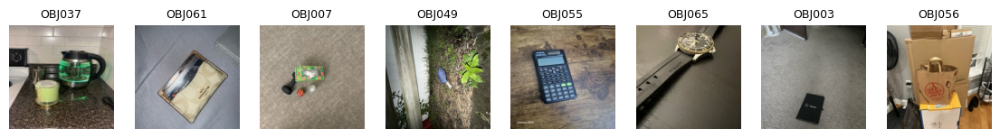

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))   # also fixes the few images that are not 224x224
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8), label   # cache as uint8 to save RAM

def make_ds(p, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y)).map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(2000, seed=SEED)
    return ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y)).prefetch(AUTOTUNE)

train_ds = make_ds(p_train, y_train, shuffle=True)
val_ds = make_ds(p_val, y_val)
test_ds = make_ds(p_test, y_test)

x, y = next(iter(train_ds))
plt.figure(figsize=(14, 3))
for i in range(min(8, len(y))):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.title(class_names[int(y[i])], fontsize=9)
    plt.axis("off")
plt.show()

## 1.3 Models

* **Data augmentation** (train only; inactive at inference): flip, rotation, zoom, shift, brightness, contrast.
  The dataset was shot under different lighting and angles, so the augmentation copies that variation.
* **Transfer learning** with two stages:
  1. *Feature extraction*: the ImageNet backbone is frozen; only the new Dropout + Dense(softmax) head is trained (lr 1e-3).
  2. *Fine-tuning*: the top block(s) of the backbone are unfrozen (BatchNorm stays frozen) and trained with lr 1e-4.
* Each backbone gets the input preprocessing it was pretrained with.
* The checkpoint with the best **validation accuracy** across both stages is kept.

In [ ]:
def make_augment():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomBrightness(0.2),
        layers.RandomContrast(0.2),
    ], name="augmentation")


@keras.saving.register_keras_serializable(package="ie7615")
class CaffePreprocess(layers.Layer):
    # ResNet50 / VGG16 preprocessing: RGB [0,255] -> BGR minus the ImageNet channel means
    def call(self, x):
        return tf.reverse(x, axis=[-1]) - tf.constant([103.939, 116.779, 123.68])


BACKBONES = {
    # name: (constructor, preprocessing layer, first backbone layer unfrozen in stage 2)
    "MobileNetV2":    (A.MobileNetV2,    lambda: layers.Rescaling(1 / 127.5, offset=-1), "block_13_expand"),
    "EfficientNetB0": (A.EfficientNetB0, None,                                            "block6a_expand_conv"),  # rescales internally
    "ResNet50":       (A.ResNet50,       CaffePreprocess,                                 "conv5_block1_1_conv"),
    "VGG16":          (A.VGG16,          CaffePreprocess,                                 "block5_conv1"),
}


def build_transfer(name):
    ctor, pre, _ = BACKBONES[name]
    base = ctor(include_top=False, weights=None if QUICK else "imagenet",
                input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    base.trainable = False
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augment()(inp)
    if pre:
        x = pre()(x)
    x = base(x, training=False)   # BatchNorm stays in inference mode, also while fine-tuning
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name=name), base


def build_custom():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = make_augment()(inp)
    x = layers.Rescaling(1 / 255.0)(x)
    for filters in [32, 64, 128, 256, 512]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name="CustomCNN")

In [ ]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])


class BestCheckpoint(keras.callbacks.Callback):
    # saves the model whenever val_accuracy improves; one instance spans both training stages
    def __init__(self, path):
        super().__init__()
        self.path, self.best = path, -1.0

    def on_epoch_end(self, epoch, logs=None):
        if logs["val_accuracy"] > self.best:
            self.best = logs["val_accuracy"]
            self.model.save(self.path)


def fit(model, epochs, patience, ckpt, extra_callbacks=()):
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=patience), ckpt, *extra_callbacks]
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2).history
    return {k: [float(v) for v in vals] for k, vals in h.items()}


def train(name):
    ckpt_path = f"{CKPT_DIR}/{name}.keras"
    ckpt = BestCheckpoint(ckpt_path)
    t0 = time.time()
    if name == "CustomCNN":
        model = build_custom()
        compile_model(model, 1e-3)
        hist = fit(model, CUSTOM_EPOCHS, 10, ckpt,
                   [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4)])
        stage1_epochs = len(hist["loss"])
    else:
        model, base = build_transfer(name)
        # Stage 1: feature extraction
        compile_model(model, 1e-3)
        hist = fit(model, HEAD_EPOCHS, 4, ckpt)
        stage1_epochs = len(hist["loss"])
        # Stage 2: fine-tune the top of the backbone
        base.trainable = True
        unfreeze = False
        for layer in base.layers:
            unfreeze = unfreeze or layer.name == BACKBONES[name][2]
            layer.trainable = unfreeze and not isinstance(layer, layers.BatchNormalization)
        compile_model(model, 1e-4)
        h2 = fit(model, FT_EPOCHS, 4, ckpt)
        hist = {k: hist[k] + h2[k] for k in hist if k in h2}
    train_min = (time.time() - t0) / 60
    best = keras.models.load_model(ckpt_path)
    return best, ckpt_path, hist, stage1_epochs, train_min


def evaluate(model, name, ckpt_path, hist, stage1_epochs, train_min):
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(1)
    val_acc = model.evaluate(val_ds, verbose=0)[1]
    x1 = tf.zeros((1, IMG_SIZE, IMG_SIZE, 3))
    for _ in range(3):
        model(x1, training=False)
    t = time.time()
    for _ in range(20):
        model(x1, training=False)
    metrics = {
        "model": name,
        "val_acc": round(float(val_acc), 4),
        "test_acc": round(float((y_pred == y_test).mean()), 4),
        "test_top5": round(float(top_k_accuracy_score(y_test, probs, k=min(5, NUM_CLASSES - 1), labels=range(NUM_CLASSES))), 4),
        "test_macro_f1": round(float(f1_score(y_test, y_pred, average="macro")), 4),
        "params_M": round(model.count_params() / 1e6, 2),
        "size_MB": round(model.count_params() * 4 / 1e6, 1),   # float32 weights
        "epochs": len(hist["loss"]),
        "stage1_epochs": stage1_epochs,
        "train_min": round(train_min, 1),
        "latency_ms_per_img": round((time.time() - t) / 20 * 1000, 1),
    }
    return metrics, probs

## 1.4 Train and evaluate all models

Order: fastest first, so the most useful results are saved early. Each finished model is written to Drive right away.

In [ ]:
ORDER = ["MobileNetV2", "EfficientNetB0", "ResNet50", "CustomCNN", "VGG16"]
results = {}

for name in ORDER:
    d = f"{OUT_DIR}/{name}"
    if os.path.exists(f"{d}/metrics.json"):
        print(f"{name}: already done, skipping")
        results[name] = json.load(open(f"{d}/metrics.json"))
        continue
    os.makedirs(d, exist_ok=True)
    print(f"\n========== {name} ==========")
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model, ckpt_path, hist, s1, train_min = train(name)
    metrics, probs = evaluate(model, name, ckpt_path, hist, s1, train_min)

    shutil.copy(ckpt_path, f"{d}/model.keras")
    np.save(f"{d}/test_probs.npy", probs)
    json.dump(hist, open(f"{d}/history.json", "w"))
    with open(f"{d}/summary.txt", "w") as f:
        model.summary(print_fn=lambda line, *a, **k: f.write(line + "\n"))
    json.dump(metrics, open(f"{d}/metrics.json", "w"), indent=1)   # written last = "done" marker
    results[name] = metrics
    print(metrics)


========== MobileNetV2 ==========
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
153/153 - 27s - 178ms/step - accuracy: 0.4116 - loss: 2.6563 - val_accuracy: 0.7732 - val_loss: 1.1195
Epoch 2/15
153/153 - 13s - 84ms/step - accuracy: 0.7567 - loss: 1.0372 - val_accuracy: 0.8431 - val_loss: 0.7311
Epoch 3/15
153/153 - 12s - 80ms/step - accuracy: 0.8346 - loss: 0.6868 - val_accuracy: 0.8632 - val_loss: 0.5886
Epoch 4/15
153/153 - 13s - 84ms/step - accuracy: 0.8650 - loss: 0.5506 - val_accuracy: 0.8842 - val_loss: 0.5014
Epoch 5/15
153/153 - 12s - 77ms/step - accuracy: 0.8859 - loss: 0.4623 - val_accuracy: 0.8813 - val_loss: 0.4660
Epoch 6/15
153/153 - 12s - 78ms/step - accuracy: 0.9005 - loss: 0.3952 - val_accuracy: 0.8794 - val_loss: 0.4553
Epoch 7/15
153/153 - 13s - 84ms/step - accuracy: 0.9122 - loss: 0.3532 - val_accuracy: 0.8947 - val_loss: 0.4086
Epoch 8/15
153/153 - 13s - 84ms/step - accuracy: 0.9192 - loss: 0.3054 - val_accuracy: 0.8967 - val_loss: 0.3778
Epoch 9/15


{'model': 'MobileNetV2', 'val_acc': 0.9617, 'test_acc': 0.9617, 'test_top5': 0.9933, 'test_macro_f1': 0.9619, 'params_M': 2.35, 'size_MB': 9.4, 'epochs': 29, 'stage1_epochs': 14, 'train_min': 7.1, 'latency_ms_per_img': 150.0}

========== EfficientNetB0 ==========
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
153/153 - 30s - 194ms/step - accuracy: 0.4795 - loss: 2.6975 - val_accuracy: 0.8211 - val_loss: 1.2450
Epoch 2/15
153/153 - 18s - 115ms/step - accuracy: 0.8076 - loss: 1.1283 - val_accuracy: 0.8708 - val_loss: 0.7227
Epoch 3/15
153/153 - 16s - 107ms/step - accuracy: 0.8683 - loss: 0.7373 - val_accuracy: 0.8938 - val_loss: 0.5485
Epoch 4/15
153/153 - 16s - 104ms/step - accuracy: 0.9001 - loss: 0.5590 - val_accuracy: 0.9091 - val_loss: 0.4513
Epoch 5/15
153/153 - 16s - 106ms/step - accuracy: 0.9165 - loss: 0.4564 - val_accuracy: 0.9148 - val_loss: 0.3865
Epoch 6/15
153/153 - 17s - 113ms/step - accuracy: 0.9302 - loss: 0.3785 - val_accuracy: 0.9330 - val_loss: 0.3418
E

{'model': 'EfficientNetB0', 'val_acc': 0.9818, 'test_acc': 0.9742, 'test_top5': 0.9971, 'test_macro_f1': 0.9743, 'params_M': 4.14, 'size_MB': 16.6, 'epochs': 30, 'stage1_epochs': 15, 'train_min': 9.9, 'latency_ms_per_img': 282.7}

========== ResNet50 ==========
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/15
153/153 - 43s - 278ms/step - accuracy: 0.4764 - loss: 2.3137 - val_accuracy: 0.8249 - val_loss: 0.7452
Epoch 2/15
153/153 - 30s - 195ms/step - accuracy: 0.8178 - loss: 0.7565 - val_accuracy: 0.8861 - val_loss: 0.4532
Epoch 3/15
153/153 - 30s - 198ms/step - accuracy: 0.8726 - loss: 0.5029 - val_accuracy: 0.9091 - val_loss: 0.3461
Epoch 4/15
153/153 - 32s - 208ms/step - accuracy: 0.9142 - loss: 0.3490 - val_accuracy: 0.9225 - val_loss: 0.2854
Epoch 5/15
153/153 - 30s - 197ms/step - accuracy: 0.9278 - loss: 0.2803 - val_accuracy: 0.9359 - val_loss: 0.2425
Epoch 6/15
153/153 - 30s - 199ms/step - accuracy: 0.9360 - loss: 0.2396 - val_accuracy: 0.9321 - val_loss: 0.2446
Epo

{'model': 'ResNet50', 'val_acc': 0.9751, 'test_acc': 0.9703, 'test_top5': 0.9962, 'test_macro_f1': 0.9702, 'params_M': 23.74, 'size_MB': 94.9, 'epochs': 28, 'stage1_epochs': 13, 'train_min': 16.5, 'latency_ms_per_img': 224.3}

========== CustomCNN ==========
Epoch 1/60
153/153 - 34s - 225ms/step - accuracy: 0.0823 - loss: 4.0828 - val_accuracy: 0.0153 - val_loss: 5.1596 - learning_rate: 0.0010
Epoch 2/60
153/153 - 25s - 163ms/step - accuracy: 0.1475 - loss: 3.5343 - val_accuracy: 0.0469 - val_loss: 4.5842 - learning_rate: 0.0010
Epoch 3/60
153/153 - 41s - 270ms/step - accuracy: 0.2142 - loss: 3.1933 - val_accuracy: 0.1789 - val_loss: 3.4560 - learning_rate: 0.0010
Epoch 4/60
153/153 - 26s - 172ms/step - accuracy: 0.2614 - loss: 2.9410 - val_accuracy: 0.2038 - val_loss: 3.4628 - learning_rate: 0.0010
Epoch 5/60
153/153 - 24s - 157ms/step - accuracy: 0.3110 - loss: 2.7305 - val_accuracy: 0.2316 - val_loss: 3.4594 - learning_rate: 0.0010
Epoch 6/60
153/153 - 24s - 156ms/step - accuracy: 0

{'model': 'CustomCNN', 'val_acc': 0.7703, 'test_acc': 0.7847, 'test_top5': 0.9263, 'test_macro_f1': 0.7852, 'params_M': 1.61, 'size_MB': 6.4, 'epochs': 55, 'stage1_epochs': 55, 'train_min': 23.2, 'latency_ms_per_img': 22.6}

========== VGG16 ==========
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/15
153/153 - 40s - 260ms/step - accuracy: 0.1321 - loss: 6.7497 - val_accuracy: 0.4986 - val_loss: 2.5517
Epoch 2/15
153/153 - 33s - 217ms/step - accuracy: 0.4216 - loss: 3.0131 - val_accuracy: 0.7033 - val_loss: 1.4359
Epoch 3/15
153/153 - 34s - 220ms/step - accuracy: 0.5683 - loss: 2.0064 - val_accuracy: 0.7914 - val_loss: 0.9620
Epoch 4/15
153/153 - 34s - 223ms/step - accuracy: 0.6586 - loss: 1.4811 - val_accuracy: 0.8220 - val_loss: 0.8004
Epoch 5/15
153/153 - 34s - 220ms/step - accuracy: 0.7204 - loss: 1.1877 - val_accuracy: 0.8507 - val_loss: 0.6278
Epoch 6/15
153/153 - 34s - 222ms/step - accuracy: 0.7483 - loss: 0.9982 - val_accuracy: 0.8536 - val_loss: 0.6160
Epoch 7/15
1

{'model': 'VGG16', 'val_acc': 0.955, 'test_acc': 0.9502, 'test_top5': 0.9866, 'test_macro_f1': 0.95, 'params_M': 14.75, 'size_MB': 59.0, 'epochs': 23, 'stage1_epochs': 15, 'train_min': 13.8, 'latency_ms_per_img': 28.7}


## 1.5 Comparison

,model,val_acc,test_acc,test_top5,test_macro_f1,params_M,size_MB,epochs,stage1_epochs,train_min,latency_ms_per_img
0,EfficientNetB0,0.9818,0.9742,0.9971,0.9743,4.14,16.6,30,15,9.9,282.7
1,ResNet50,0.9751,0.9703,0.9962,0.9702,23.74,94.9,28,13,16.5,224.3
2,MobileNetV2,0.9617,0.9617,0.9933,0.9619,2.35,9.4,29,14,7.1,150.0
3,VGG16,0.9550,0.9502,0.9866,0.9500,14.75,59.0,23,15,13.8,28.7
4,CustomCNN,0.7703,0.7847,0.9263,0.7852,1.61,6.4,55,55,23.2,22.6


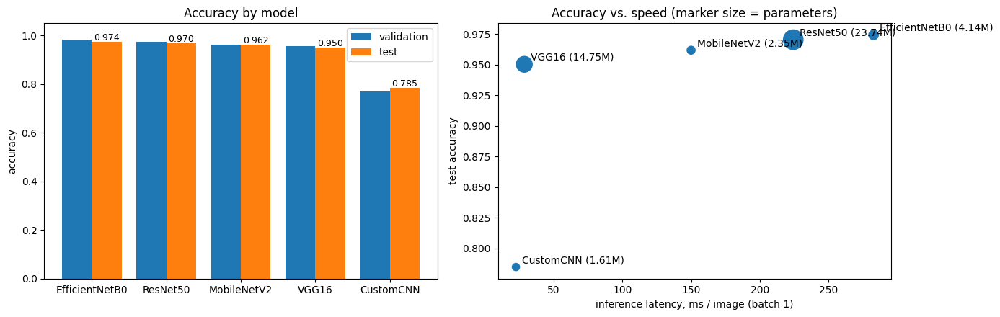

In [ ]:
df = pd.DataFrame([results[n] for n in ORDER if n in results]).sort_values("val_acc", ascending=False).reset_index(drop=True)
df.to_csv(f"{OUT_DIR}/model_comparison.csv", index=False)
display(df)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(df))
ax[0].bar(x - 0.2, df.val_acc, 0.4, label="validation")
ax[0].bar(x + 0.2, df.test_acc, 0.4, label="test")
for i, v in enumerate(df.test_acc):
    ax[0].text(i + 0.2, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
ax[0].set_xticks(x); ax[0].set_xticklabels(df.model); ax[0].set_ylim(0, 1.05)
ax[0].set_ylabel("accuracy"); ax[0].set_title("Accuracy by model"); ax[0].legend()
ax[1].scatter(df.latency_ms_per_img, df.test_acc, s=df.params_M * 15 + 30)
for _, r in df.iterrows():
    ax[1].annotate(f"{r.model} ({r.params_M}M)", (r.latency_ms_per_img, r.test_acc), textcoords="offset points", xytext=(6, 4))
ax[1].set_xlabel("inference latency, ms / image (batch 1)"); ax[1].set_ylabel("test accuracy")
ax[1].set_title("Accuracy vs. speed (marker size = parameters)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/accuracy_comparison.png", dpi=150); plt.show()

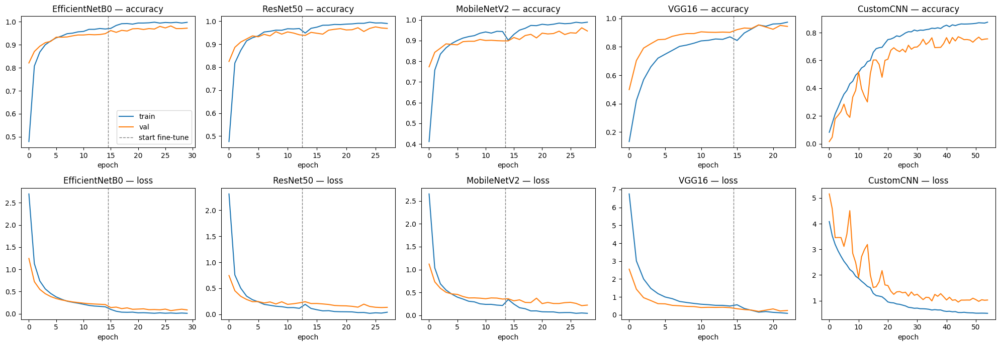

In [ ]:
names = list(df.model)
fig, axes = plt.subplots(2, len(names), figsize=(4 * len(names), 7), squeeze=False)
for j, name in enumerate(names):
    h = json.load(open(f"{OUT_DIR}/{name}/history.json"))
    s1 = results[name]["stage1_epochs"]
    for i, (k, title) in enumerate([("accuracy", "accuracy"), ("loss", "loss")]):
        a = axes[i, j]
        a.plot(h[k], label="train"); a.plot(h["val_" + k], label="val")
        if name != "CustomCNN":
            a.axvline(s1 - 0.5, color="gray", ls="--", lw=1, label="start fine-tune")
        a.set_title(f"{name} — {title}"); a.set_xlabel("epoch")
axes[0, 0].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/learning_curves.png", dpi=150); plt.show()

## 1.6 Best model: error analysis

The best model is selected by **validation** accuracy (the test set is only used for reporting).

Best model: EfficientNetB0 | test accuracy 0.9742


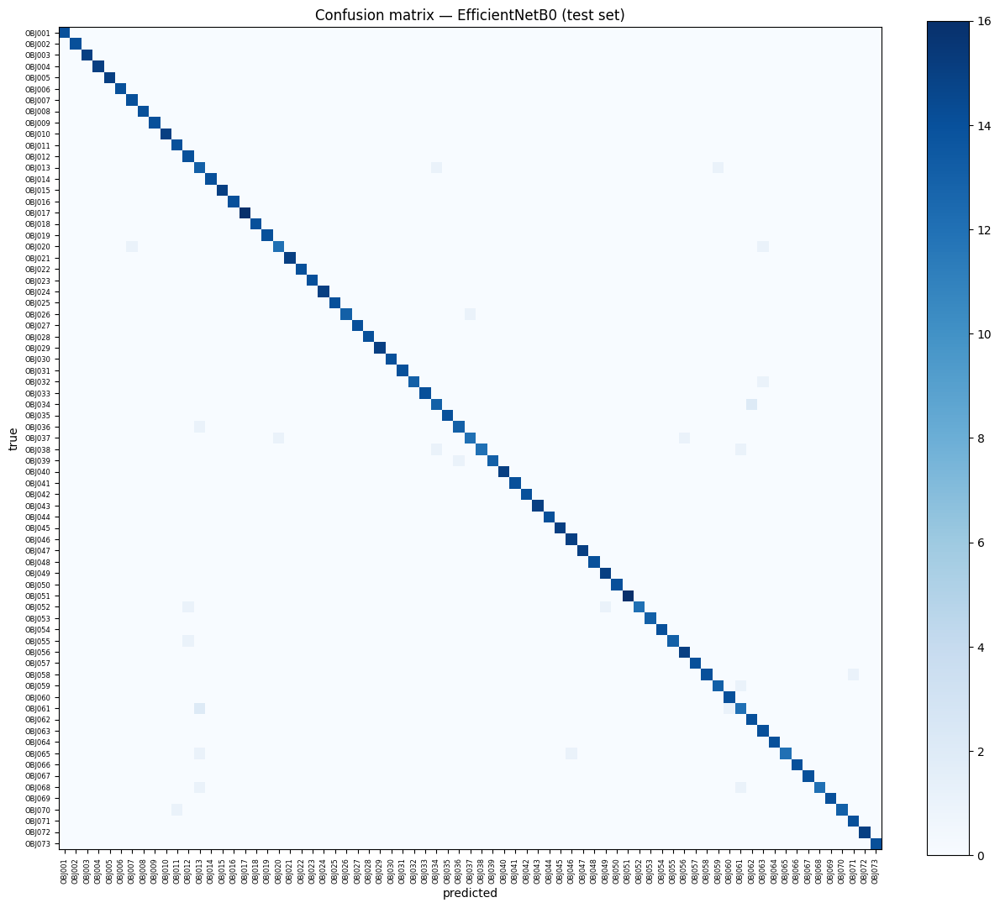

Lowest-recall classes:


,precision,recall,f1-score,support
OBJ061,0.800000,0.800000,0.800000,15.0
OBJ020,0.923077,0.857143,0.888889,14.0
OBJ038,1.000000,0.857143,0.923077,14.0
OBJ052,1.000000,0.857143,0.923077,14.0
OBJ037,0.923077,0.857143,0.888889,14.0
OBJ065,1.000000,0.857143,0.923077,14.0
OBJ068,1.000000,0.857143,0.923077,14.0
OBJ013,0.722222,0.866667,0.787879,15.0
OBJ034,0.866667,0.866667,0.866667,15.0
OBJ039,1.000000,0.928571,0.962963,14.0


Most confused pairs (true -> predicted, count):


,true,predicted,count
0,OBJ061,OBJ013,2
1,OBJ034,OBJ062,2
2,OBJ059,OBJ061,1
3,OBJ065,OBJ013,1
4,OBJ065,OBJ046,1
5,OBJ070,OBJ011,1
6,OBJ068,OBJ061,1
7,OBJ039,OBJ036,1
8,OBJ013,OBJ059,1
9,OBJ037,OBJ056,1


In [ ]:
BEST = df.model[0]
shutil.copy(f"{OUT_DIR}/{BEST}/model.keras", f"{OUT_DIR}/best_model.keras")
probs = np.load(f"{OUT_DIR}/{BEST}/test_probs.npy")
y_pred = probs.argmax(1)
print(f"Best model: {BEST} | test accuracy {(y_pred == y_test).mean():.4f}")

cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
plt.figure(figsize=(12, 11))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(NUM_CLASSES), class_names, rotation=90, fontsize=6)
plt.yticks(range(NUM_CLASSES), class_names, fontsize=6)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"Confusion matrix — {BEST} (test set)")
plt.colorbar(fraction=0.046)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix_best.png", dpi=150); plt.show()

report = pd.DataFrame(classification_report(y_test, y_pred, labels=range(NUM_CLASSES), target_names=class_names,
                                            output_dict=True, zero_division=0)).T
report.to_csv(f"{OUT_DIR}/per_class_report_best.csv")
print("Lowest-recall classes:")
display(report.iloc[:NUM_CLASSES].sort_values("recall").head(10))

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(class_names[i], class_names[j], off[i, j]) for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1], off.shape)) if off[i, j] > 0][:10]
print("Most confused pairs (true -> predicted, count):")
display(pd.DataFrame(pairs, columns=["true", "predicted", "count"]))

27 misclassified test images out of 1045


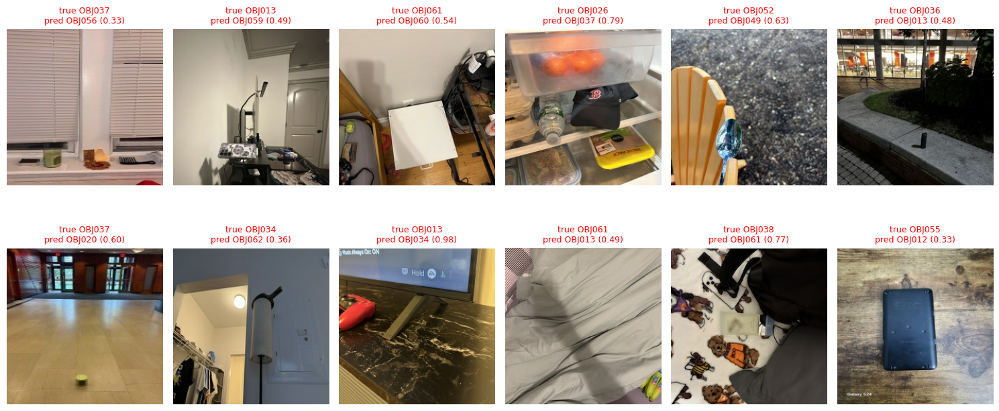

In [ ]:
wrong = np.where(y_pred != y_test)[0]
print(f"{len(wrong)} misclassified test images out of {len(y_test)}")
n = min(12, len(wrong))
if n:
    plt.figure(figsize=(15, 3.6 * ((n + 5) // 6)))
    for k, i in enumerate(wrong[:n]):
        plt.subplot((n + 5) // 6, 6, k + 1)
        img = load_image(p_test[i], 0)[0].numpy()
        plt.imshow(img)
        plt.title(f"true {class_names[y_test[i]]}\npred {class_names[y_pred[i]]} ({probs[i].max():.2f})", fontsize=9, color="red")
        plt.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/misclassified_best.png", dpi=120); plt.show()

## 1.7 Demo: identify OBJ036

The demo uses only OBJ036 images from the **test split**, which the model never saw during training.
For a live demo, take a new photo of OBJ036 (JPG) and run the last cell.

In [ ]:
from PIL import Image, ImageOps

best_model = keras.models.load_model(f"{OUT_DIR}/best_model.keras")

def load_photo(path):
    # new phone photos: apply the EXIF rotation, center-crop to a square, resize to 224x224
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    s = min(im.size)
    left, top = (im.width - s) // 2, (im.height - s) // 2
    return np.asarray(im.crop((left, top, left + s, top + s)).resize((IMG_SIZE, IMG_SIZE)))

def predict_image(path, model=best_model, top=3, new_photo=False):
    img = load_photo(path) if new_photo else load_image(path, 0)[0].numpy()
    p = model.predict(img[None].astype("float32"), verbose=0)[0]
    order = p.argsort()[::-1][:top]
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[order[0]]}  ({p[order[0]]:.1%})"); plt.show()
    return [(class_names[i], round(float(p[i]), 4)) for i in order]

In [ ]:
DEMO_ID = "OBJ036"
demo_label = class_names.index(DEMO_ID)
demo_paths = p_test[y_test == demo_label]   # test split only: never seen in training

x = np.stack([load_image(p, 0)[0].numpy() for p in demo_paths]).astype("float32")
demo_probs = best_model.predict(x, verbose=0)
demo_pred = demo_probs.argmax(1)
print(f"{BEST}: {int((demo_pred == demo_label).sum())} / {len(demo_paths)} unseen {DEMO_ID} test images identified correctly")

cols = 7
rows = -(-len(demo_paths) // cols)
plt.figure(figsize=(2.4 * cols, 2.8 * rows))
for k in range(len(demo_paths)):
    ok = demo_pred[k] == demo_label
    plt.subplot(rows, cols, k + 1)
    plt.imshow(x[k].astype("uint8")); plt.axis("off")
    plt.title(f"{'✓' if ok else '✗'} {class_names[demo_pred[k]]} ({demo_probs[k].max():.0%})",
              fontsize=9, color="#006300" if ok else "#d03b3b")
plt.suptitle(f"{DEMO_ID}: predictions on unseen test images", y=1.02)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/demo_{DEMO_ID}.png", dpi=120, bbox_inches="tight"); plt.show()

In [ ]:
# one test image of OBJ036 with its top-3 predictions (try indices 0 to len(demo_paths) - 1)
predict_image(demo_paths[0])

# live demo with a new photo: uncomment, run, and upload a JPG of OBJ036
# (iPhone: Settings > Camera > Formats > Most Compatible, so photos are JPG instead of HEIC)
# from google.colab import files
# uploaded = files.upload()
# predict_image(list(uploaded)[0], new_photo=True)

## 1.8 Milestone 1 conclusion

Test set: 1,045 photos (15%), never used for training or for choosing the model.

| Model | Val accuracy | Test accuracy | Top-5 | Macro F1 | Parameters | Train time |
|---|---|---|---|---|---|---|
| **EfficientNetB0 (two-stage fine-tuning)** | **98.2%** | **97.4%** | 99.7% | **0.974** | 4.14 M | 9.9 min |
| ResNet50 | 97.5% | 97.0% | 99.6% | 0.970 | 23.74 M | 16.5 min |
| MobileNetV2 | 96.2% | 96.2% | 99.3% | 0.962 | 2.35 M | 7.1 min |
| VGG16 | 95.5% | 95.0% | 98.7% | 0.950 | 14.75 M | 13.8 min |
| Custom CNN (from scratch) | 77.0% | 78.5% | 92.6% | 0.785 | 1.61 M | 23.2 min |

* **Transfer learning wins by a large margin.** With about 67 training photos per class, the CNN trained from scratch
  reaches 78.5%; every ImageNet model reaches 95% or more.
* **EfficientNetB0 is the best model** (chosen on validation accuracy): 97.4% test accuracy and macro F1 0.974, with
  4.1 M parameters (ResNet50 needs 23.7 M for 97.0%). 27 of the 1,045 test photos are wrong.
* **Errors** are mostly between similar-looking objects, e.g. OBJ061 → OBJ013 and OBJ034 → OBJ062 (2 photos each).
  Our object OBJ038 was found in 12 of its 14 test photos (recall 0.857).

**Limitation → next step:** a classifier outputs one label per image. The project's next task needs every object in an
image **and its location**, so Part 2 moves to object detection. The transfer-learning idea carries over.

> **Before Part 2:** *Runtime → Restart session* (frees the GPU memory used by TensorFlow).

---
# Part 2 — Milestone 2: Multi-object detection and location (YOLOv8s)

**Goal:** given one image with many objects, report **every object's ID and its bounding box**.
The dataset only has class labels, so we first create boxes, then build multi-object grid images and fine-tune YOLOv8s.
The final model's evaluation and demo are in **Part 3**.

### What changed during Milestone 2, and why
In the notes below, **v1** means our first Milestone 2 notebook. Rows marked *final* were added for the final model.

| # | Change | Reason (instructors' clarifications) |
|---|---|---|
| 1 | Multi-object images are **grids of 224 × 224 photos placed side by side**: 2×2, 3×3, 4×4, 5×4 and 5×5 (up to 1120 × 1120). v1 pasted 2–5 resized photos onto a 640 × 640 background. | §2 Grid images, and the report must state the grid sizes used |
| 2 | Each box surrounds **the object inside the photo**, created by two open-vocabulary detectors (**YOLO-World** and **Grounding DINO**) that check each other. v1 used the whole pasted photo as the box, which is why mAP@0.5 and mAP@0.5:0.95 were identical. | §3 Labelling: create boxes, check a sample, report photos left out |
| 3 | **Exact duplicate photos are removed before the split.** v1 had 13 groups of identical photos in different splits (5 test photos had a copy in train). | §4 and §5: no copy in more than one split |
| 4 | **OBJ054_017 is excluded.** | §4 |
| 5 | Every photo is resized to 224 × 224 (fixes OBJ003_072 and OBJ023_001) and its EXIF rotation is applied. | §4 |
| 6 | Background-only photos (`_bg_`) are **not used**: grids have no background. This also removes the 5 OBJ065 `_bg_` files, which are copies of OBJ065 object photos. | §2 |
| 7 | `imgsz=1120`, `batch=8`, checkpoints saved to Google Drive, training resumes after a disconnect. | §2 tip |
| 8 | Photos left out per Object ID (and why), label check figures, metrics per grid size and per Object ID, training curves, confusion matrix, example detections and an error analysis. | §3, §4, §5 report items |
| 9 | Results are saved to our own Google Drive. Nothing is written to the shared dataset folder, and only this notebook goes to GitHub. | §5 |
| 10 | *Final:* **1,200 train grids** (up from 800), trained for 60 epochs. | More training data for the final model |
| 11 | *Final:* the dataset is found automatically in My Drive, and box labels from the group's Milestone 2 run are reused if present (saves ~40 min). | Easier to re-run |
| 12 | *Final:* both group objects (`FOCUS_IDS`) are highlighted, and **3.4** runs the trained model on new images for the live demo. | Milestone 3 presentation and demo |
| 13 | *Final:* **22 wrong box labels corrected by hand and 1 photo removed** (OBJ004 Toy Car, OBJ011 Mug, OBJ040 Clutcher), found in the Milestone 3 error analysis; then a review of all labels left out 202 more train / val photos with a wrong box. The labelling models had boxed another object (a laptop, a jar, a different mug) or the whole photo (see 2.5.3). Results go to `milestone3_v2/`. | Wrong labels taught the model wrong boxes, e.g. a laptop detected as OBJ040 |

### How to run Parts 2–3 (Google Colab)
1. Put `database.zip` (or the unzipped `images_OBJxxx` folders) anywhere in My Drive, up to 3 folders deep. It is found automatically; or set `DATASET_SOURCE` in 2.2.
2. *Runtime → Change runtime type → T4 GPU*. Restart the session if Part 1 was just run, then run all cells from here.
3. Results go to `My Drive/milestone3_v2/`. If Colab disconnects, run again from here:
   the box labels are reloaded from Drive and training continues from the last epoch.

**Run time on a T4: about 2 hours from scratch** (our run: 117 min — labelling 42 min, grids 1 min, training 57 min, evaluation 2 min). With cached labels and a finished training run, ~10–15 min. With the label caches of `milestone2_final/` and the corrected box labels, about 70 min (training ~57 min).

## 2.1 Mount Google Drive

> **Note:** unchanged from Milestone 2. The `if` lets the same code also run outside Colab for a quick local test.

In [1]:
import sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

Mounted at /content/drive


## 2.2 Paths and settings

> **Note (changed for the final model):** the dataset is found automatically: the code looks for `database.zip` or the
> `images_OBJxxx` folders anywhere in My Drive (up to 3 folders deep), or uses `DATASET_SOURCE` if it is set. The dataset
> is copied to `/content/database` (local disk: much faster than reading from Drive).
> Outputs (labels, figures, model weights) are saved to `My Drive/milestone3_v2/`, so the results before the label fixes
> (`milestone2_final/`) are kept for comparison. Box-label caches from the previous runs (`milestone2_final/labels`, or
> `Project1/week2_results/labels`) are reused if they exist. Grid images are built on the Colab disk and a
> zip copy is kept in our Drive. Nothing is uploaded to the shared class folder.
>
> All settings are in this one cell: grid sizes, number of grid images, model settings.
> `FOCUS_IDS` lists our group's objects, which are highlighted in the results.
> `QUICK=1` is only for a local smoke test (3 objects, tiny models, 1 epoch). It is off on Colab.

In [2]:
import os, re, sys, json, time, glob, shutil, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps, ImageEnhance
from IPython.display import display
import torch

IN_COLAB = "google.colab" in sys.modules
QUICK = os.environ.get("QUICK") == "1"          # local smoke test only
GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if GPU else "none (Runtime -> Change runtime type -> GPU)")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    MYDRIVE = "/content/drive/MyDrive"
    OUT_DIR = f"{MYDRIVE}/milestone3_v2"         # our own Drive folder; nothing is ever written to the shared class folder
    WORK_DIR = "/content"
else:
    MYDRIVE = os.environ.get("MYDRIVE", "mydrive")
    OUT_DIR = os.environ.get("OUT_DIR", "milestone3_v2")
    WORK_DIR = os.environ.get("WORK_DIR", "work")
DATA_DIR = f"{WORK_DIR}/database"               # local copy of the dataset (fast)
PHOTO_DIR = f"{WORK_DIR}/photos224"             # cleaned 224 x 224 single photos
for d in [OUT_DIR, f"{OUT_DIR}/labels", f"{OUT_DIR}/figures", PHOTO_DIR, WORK_DIR]:
    os.makedirs(d, exist_ok=True)

# ---------- find the dataset: database.zip or the unzipped images_OBJxxx folders, anywhere up to 3 folders deep ----------
DATASET_SOURCE = None    # set a path here to skip the search, e.g. "/content/drive/MyDrive/IE7615 Deep Learning for AI"

def find_dataset():
    for depth in range(4):
        pat = "/".join(["*"] * depth)
        for z in sorted(glob.glob(f"{MYDRIVE}/{pat}/database.zip".replace("//", "/"))):
            return z
        for d in sorted(glob.glob(f"{MYDRIVE}/{pat}/images_OBJ001".replace("//", "/"))):
            return os.path.dirname(d)
    return None

if not os.path.isdir(DATA_DIR) or not glob.glob(f"{DATA_DIR}/images_OBJ*"):
    src = DATASET_SOURCE or find_dataset()
    assert src, "dataset not found: set DATASET_SOURCE to the folder with images_OBJ001 ... or to database.zip"
    print("copying dataset from", src)
    if src.endswith(".zip"):
        with zipfile.ZipFile(src) as z:
            z.extractall(WORK_DIR)
    else:
        for d in sorted(glob.glob(f"{src}/images_OBJ*")):
            shutil.copytree(d, f"{DATA_DIR}/{os.path.basename(d)}", dirs_exist_ok=True)
print("object folders:", len(glob.glob(f"{DATA_DIR}/images_OBJ*")))

# ---------- settings ----------
SEED = 42
FOCUS_IDS = ["OBJ036", "OBJ038"]       # our group's objects, highlighted in the results (add the other two)
FOCUS_ID = FOCUS_IDS[0]                # the object drawn with a thick box in the example detections (3.2)
EXCLUDE = {"OBJ054_017"}               # instructor note: not a photo of the object
TILE = 224
GRID_SIZES = [(2, 2), (3, 3), (4, 4), (5, 4), (5, 5)]          # (columns, rows)
N_GRIDS = {"train": 1200, "val": 150, "test": 150}
GRID_SEEDS = {"train": 1, "val": 2, "test": 3}
IMGSZ, EPOCHS, PATIENCE, CONF = 1120, 60, 15, 0.5
DET_WEIGHTS, RUN_NAME = "yolov8s.pt", "final_yolov8s_v4"        # v4: + UNO boxes (v3: pencil case, sneaker pairs; v2: label review)
BATCH = 8 if DET_WEIGHTS == "yolov8s.pt" else 4
SINGLE_IMGSZ = 448                     # a 224 px photo is enlarged 2x, as a tile is in a 2x2 grid
YW_WEIGHTS = "yolov8x-worldv2.pt"
GD_MODEL, GD_SIZE = "IDEA-Research/grounding-dino-tiny", 640
TOPK, AGREE_IOU, GD_SURE, YW_SURE, MAX_LEFT_OUT = 3, 0.5, 0.35, 0.20, 0.20
REFINE_CONF, REFINE_IOU = 0.5, 0.3     # round-1 detector "confidently contradicts" a box: score >= 0.5 and IoU < 0.3
R1_EPOCHS = 25
CLASS_IDS, PHOTOS_PER_CLASS = None, None

# a round-1 detector trained on the SAME train split can be reused (e.g. the group's v2 model) to save ~30 minutes
ROUND1_CANDIDATES = [f"{OUT_DIR}/round1.pt",
                     f"{MYDRIVE}/NEU/IE7615 Deep Learning for AI/Project1/week2_results/best_yolov8s_grid.pt"]
# label caches from earlier runs (same prompts, same photos) save ~40 minutes of labelling
PREVIOUS_LABELS = [f"{MYDRIVE}/milestone2_final/labels",          # final run before the label fixes
                   f"{MYDRIVE}/NEU/IE7615 Deep Learning for AI/Project1/week2_results/labels"]   # group's v2 run
for f in ["yoloworld_raw.json", "gdino_raw.json"]:
    src = next((f"{d}/{f}" for d in PREVIOUS_LABELS if os.path.exists(f"{d}/{f}")), None)
    if src and not os.path.exists(f"{OUT_DIR}/labels/{f}"):
        shutil.copy(src, f"{OUT_DIR}/labels/{f}")
        print("reusing label cache", src)

if QUICK:
    CLASS_IDS, PHOTOS_PER_CLASS = ["OBJ001", "OBJ007", "OBJ036"], 20
    GRID_SIZES, N_GRIDS = [(2, 2), (3, 2)], {"train": 8, "val": 4, "test": 4}
    DET_WEIGHTS, RUN_NAME, IMGSZ, BATCH, EPOCHS, PATIENCE, R1_EPOCHS = "yolov8n.pt", "quick", 320, 4, 1, 1, 1
    ROUND1_CANDIDATES = [f"{OUT_DIR}/round1.pt"]

TIMES, T_START = {}, time.time()
print("outputs ->", OUT_DIR)

GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
copying dataset from /content/drive/MyDrive/NEU/IE7615 Deep Learning for AI/Project1/database.zip
object folders: 73
outputs -> /content/drive/MyDrive/milestone3_v2


## 2.3 Install Ultralytics and check the GPU

> **Note (moved up):** Ultralytics is now installed before the labelling step, because YOLO-World (used to create
> the boxes in 2.5) is part of Ultralytics.

In [3]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 9.8 MB/s eta 0:00:00


In [4]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
GPU = torch.cuda.is_available()
DEVICE = 0 if GPU else "cpu"

GPU available: True
GPU name: Tesla T4


## 2.4 Single photos: clean, remove duplicates, split

> **Note (changed):**
> * Background-only photos (`_bg_`) are not used any more: grid images have no background.
> * `OBJ054_017` is excluded (instructor note: not a photo of the object).
> * Every photo is saved once as a clean 224 × 224 RGB copy with its **EXIF rotation applied**. Some phone photos
>   carry a rotation flag; YOLO (OpenCV) applies it but PIL does not, which would shift the boxes. Photos that are not
>   224 × 224 (one in OBJ003) are resized here.
> * **Exact duplicates are removed before the split** (pixel-identical photos). One copy is kept. If the same
>   photo appeared under two Object IDs, all copies would be dropped because the label would be ambiguous.
> * The split uses the same rule as Milestone 1 (70 / 15 / 15 per class, seed 42), now made **after** the duplicates are
>   removed (so the photo counts differ slightly from Part 1). A check at the end confirms that no photo (or copy of it) is in more than one split.

In [5]:
from sklearn.model_selection import train_test_split
from PIL import Image, ImageOps, ImageEnhance

t0 = time.time()
IMG_RE = re.compile(r"\.jpe?g$", re.I)
BG_RE = re.compile(r"_bg_", re.I)

folders = sorted(d for d in os.listdir(DATA_DIR) if d.startswith("images_OBJ"))
if CLASS_IDS:
    folders = [d for d in folders if d.replace("images_", "") in CLASS_IDS]
class_names = [d.replace("images_", "") for d in folders]

rows, removed = [], []
for i, d in enumerate(folders):
    files = sorted(f for f in os.listdir(os.path.join(DATA_DIR, d)) if IMG_RE.search(f) and not BG_RE.search(f))
    for f in files[:PHOTOS_PER_CLASS]:
        stem = os.path.splitext(f)[0]
        if stem in EXCLUDE:
            removed.append((stem, class_names[i], "excluded: not a photo of the object (instructor note)"))
            continue
        im = ImageOps.exif_transpose(Image.open(os.path.join(DATA_DIR, d, f))).convert("RGB")
        digest = hashlib.md5(im.tobytes() + str(im.size).encode()).hexdigest()   # identical pixels -> identical hash
        size = im.size
        if size != (TILE, TILE):
            im = im.resize((TILE, TILE), Image.BICUBIC)
        im.save(f"{PHOTO_DIR}/{stem}.jpg", quality=95)
        rows.append(dict(stem=stem, label=i, obj_id=class_names[i], src=f"{d}/{f}", photo=f"{PHOTO_DIR}/{stem}.jpg",
                         orig_size=f"{size[0]}x{size[1]}", hash=digest))
photos = pd.DataFrame(rows)
assert photos.stem.is_unique

# exact duplicates: handled BEFORE splitting
keep = pd.Series(True, index=photos.index)
for _, g in photos.groupby("hash"):
    if len(g) == 1:
        continue
    if g.obj_id.nunique() > 1:
        drop, why = g.index, "same photo under several Object IDs: " + ", ".join(g.stem)
    else:
        drop, why = g.index[1:], f"exact duplicate of {g.stem.iloc[0]}"
    for k in drop:
        keep[k] = False
        removed.append((photos.stem[k], photos.obj_id[k], why))
photos = photos[keep].reset_index(drop=True)
removed = pd.DataFrame(removed, columns=["stem", "obj_id", "reason"])

# same split as Milestone 1 (stratified 70/15/15, seed 42), on the de-duplicated photos
idx_train, idx_tmp = train_test_split(photos.index.values, test_size=0.30, stratify=photos.label, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=photos.label.loc[idx_tmp], random_state=SEED)
photos["split"] = "train"
photos.loc[idx_val, "split"] = "val"
photos.loc[idx_test, "split"] = "test"

hashes = {s: set(photos.hash[photos.split == s]) for s in ["train", "val", "test"]}
assert not (hashes["train"] & hashes["val"] or hashes["train"] & hashes["test"] or hashes["val"] & hashes["test"])
print("check passed: no photo (or copy of it) is in more than one split")

photos.drop(columns="photo").to_csv(f"{OUT_DIR}/photos_split.csv", index=False)
removed.to_csv(f"{OUT_DIR}/removed_photos.csv", index=False)
print(f"Classes: {len(class_names)} | unique object photos: {len(photos)} | "
      + " | ".join(f"{s} {n}" for s, n in photos.split.value_counts().items()))
print("Resized (not 224x224):", photos.loc[photos.orig_size != "224x224", ["src", "orig_size"]].values.tolist())
print(f"Removed before the split: {len(removed)}")
display(removed)
TIMES["photos"] = (time.time() - t0) / 60

check passed: no photo (or copy of it) is in more than one split
Classes: 73 | unique object photos: 6947 | train 4862 | test 1043 | val 1042
Resized (not 224x224): [['images_OBJ003/OBJ003_072.jpg', '224x192'], ['images_OBJ023/OBJ023_001.JPG', '225x224']]
Removed before the split: 17


,stem,obj_id,reason
0,OBJ054_017,OBJ054,excluded: not a photo of the object (instructo...
1,OBJ011_026,OBJ011,exact duplicate of OBJ011_024
2,OBJ029_083,OBJ029,exact duplicate of OBJ029_006
3,OBJ062_095,OBJ062,exact duplicate of OBJ062_039
4,OBJ062_037,OBJ062,exact duplicate of OBJ062_009
5,OBJ023_086,OBJ023,exact duplicate of OBJ023_036
6,OBJ066_082,OBJ066,exact duplicate of OBJ066_081
7,OBJ011_025,OBJ011,exact duplicate of OBJ011_023
8,OBJ023_089,OBJ023,exact duplicate of OBJ023_050
9,OBJ023_085,OBJ023,exact duplicate of OBJ023_034


## 2.5 Bounding boxes for every single photo

> **Note (new):** the shared dataset only has class labels (folder names), no boxes. Each photo shows **one** object,
> so it needs one box around that object. v1 used the whole photo as the box. Here two different
> open-vocabulary detectors look for the object, prompted with a short name of it:
>
> * **YOLO-World v2 (x)**, from Ultralytics
> * **Grounding DINO (tiny)**, from Hugging Face
>
> The two models check each other (instructor tip: "comparing the boxes from two different models is a good way to
> catch mistakes"):
>
> | Status | Rule | Used in grids? |
> |---|---|---|
> | `agree` | the two top boxes overlap with IoU ≥ 0.5 → final box = average of the two | yes |
> | `agree_2nd_choice` | one model's 2nd/3rd candidate matches the other model's box | yes |
> | `gdino_only` / `yoloworld_only` | no agreement, but one model is confident (score ≥ 0.35 / 0.20) | yes, shown in the check figure |
> | `rescued` | not reliable, but leaving it out would drop more than 20% of that object's photos | yes, shown in the check figure |
> | `left_out` | neither model found the object reliably | no, counted per Object ID |
>
> The prompts are the **OBJECT_NAME of each Object ID in the class sheet** (`Milestone-1 _ OBJECTS.pdf`). The one
> change is a spelling fix, "Swimming Goggels" → "Swimming Goggles", so the text encoders recognise the word.
> Raw boxes are cached in `milestone3_v2/labels/`, so this step runs only once (~42 min on a T4 in our run:
> YOLO-World 15 min, Grounding DINO 27 min). Caches from the previous runs (`milestone2_final/`) are reused if present.
> If `PROMPTS` is changed after a run, delete `yoloworld_raw.json` and `gdino_raw.json` there so the boxes are made again.

In [6]:
PROMPTS = {   # OBJECT_NAME from the class sheet "Milestone-1 _ OBJECTS.pdf"
    "OBJ001": "Basketball", "OBJ002": "Water Bottle", "OBJ003": "NoteBook", "OBJ004": "Toy Car",
    "OBJ005": "Computer Mouse", "OBJ006": "Capybara Toy", "OBJ007": "Apple", "OBJ008": "Cat",
    "OBJ009": "Marshall Speaker", "OBJ010": "Nike Sneakers", "OBJ011": "Mug", "OBJ012": "Computer Keyboard",
    "OBJ013": "Mobile Phone", "OBJ014": "Sunglasses", "OBJ015": "Water Tumbler", "OBJ016": "Sandisk Portable SSD",
    "OBJ017": "Controller", "OBJ018": "Rubiks Cube", "OBJ019": "Plant", "OBJ020": "Airpod",
    "OBJ021": "Toy Bunny", "OBJ022": "Guitar", "OBJ023": "Bracelet", "OBJ024": "Plush Doll",
    "OBJ025": "Watch", "OBJ026": "Red Sox Cap", "OBJ027": "Tennis Ball", "OBJ028": "Banana",
    "OBJ029": "Orange", "OBJ030": "Tennis Racket", "OBJ031": "UNO Card Box", "OBJ032": "Sound Card",
    "OBJ033": "Duck", "OBJ034": "Table Tennis Racket", "OBJ035": "Badminton Racket", "OBJ036": "Pencil Case",
    "OBJ037": "Candle", "OBJ038": "Perfume Bottle", "OBJ039": "Scissors", "OBJ040": "Clutcher",
    "OBJ041": "Table Fan", "OBJ042": "Mouth Guard Case", "OBJ043": "Swimming Goggles", "OBJ044": "Anime Figurine",
    "OBJ045": "Wayfarer Sunglasses", "OBJ046": "IWatch", "OBJ047": "Backpack", "OBJ048": "Wireless Powerbank",
    "OBJ049": "Pickleball Bat", "OBJ050": "Hairbrush", "OBJ051": "Tissue", "OBJ052": "Spoon",
    "OBJ053": "Moisturizer", "OBJ054": "Purse", "OBJ055": "Scientific Calculator", "OBJ056": "Trader Joe's Bag",
    "OBJ057": "Power Bank", "OBJ058": "Footstool", "OBJ059": "Comb", "OBJ060": "Sleep Mask",
    "OBJ061": "Card Wallet", "OBJ062": "Headphones", "OBJ063": "Measuring Bottle", "OBJ064": "RGB Projector",
    "OBJ065": "Analog Watch", "OBJ066": "Hair Oil", "OBJ067": "Men's Wallet", "OBJ068": "Neck Pillow",
    "OBJ069": "Knife", "OBJ070": "Astronaut Projector", "OBJ071": "Sloth Plushie", "OBJ072": "Dog",
    "OBJ073": "Bowl",
}
assert all(c in PROMPTS for c in class_names), "add a prompt for every Object ID"
TOPK = 3                         # candidate boxes kept per model and photo
AGREE_IOU = 0.5                  # the two models agree when their boxes overlap with IoU >= 0.5
GD_SURE, YW_SURE = 0.35, 0.20    # a single model's box is accepted only above these scores
MAX_LEFT_OUT = 0.20              # instructor rule: leave out at most 20% of the photos of an Object ID


def load_cache(path):
    return json.load(open(path)) if os.path.exists(path) else {}


def to_list(xyxy, scores):
    return [[round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1), round(s, 4)]
            for (x1, y1, x2, y2), s in zip(xyxy, scores)]

### 2.5.1 Model 1: YOLO-World

> **Note:** one prompt per Object ID at a time, so similar objects (e.g. the two wristwatches OBJ025 / OBJ065) do not
> compete with each other. Photos are sent in groups of 16 so the GPU does not run out of memory. The top 3 boxes per photo are kept, with a low score threshold. Low-score boxes are
> only accepted when Grounding DINO agrees.

In [7]:
t0 = time.time()
YW_CACHE = f"{OUT_DIR}/labels/yoloworld_raw.json"
yw_raw = load_cache(YW_CACHE)
todo = photos[~photos.stem.isin(yw_raw)]
if len(todo):
    from ultralytics import YOLOWorld
    yw = YOLOWorld(YW_WEIGHTS)
    for n, (oid, g) in enumerate(todo.groupby("obj_id")):
        yw.set_classes([PROMPTS[oid]])
        for i in range(0, len(g), 16):   # 16 photos at a time: a whole list is run as one batch and fills the GPU
            chunk = g.iloc[i:i + 16]
            res = yw.predict(list(chunk.photo), imgsz=640, conf=0.01, iou=0.5, max_det=TOPK, device=DEVICE, verbose=False)
            for stem, r in zip(chunk.stem, res):
                yw_raw[stem] = to_list(r.boxes.xyxy.tolist(), r.boxes.conf.tolist())
        json.dump(yw_raw, open(YW_CACHE, "w"))   # saved after every Object ID
        print(f"\rYOLO-World: {n + 1}/{todo.obj_id.nunique()} Object IDs", end="")
    del yw
    if GPU:
        torch.cuda.empty_cache()
print(f"\nYOLO-World boxes for {len(yw_raw)} photos ({(time.time() - t0) / 60:.1f} min)")
TIMES["label_yoloworld"] = (time.time() - t0) / 60


YOLO-World boxes for 6947 photos (0.0 min)


### 2.5.2 Model 2: Grounding DINO

> **Note:** the same prompt, written in lower case and ending with "." as Grounding DINO expects. The photos are only
> 224 × 224, so the model input is set to 640 instead of the default 800, which makes it faster. Near-identical
> candidate boxes are merged with NMS.

In [8]:
t0 = time.time()
GD_CACHE = f"{OUT_DIR}/labels/gdino_raw.json"
gd_raw = load_cache(GD_CACHE)
todo = photos[~photos.stem.isin(gd_raw)]
if len(todo):
    from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
    from torchvision.ops import nms
    hf_dev = "cuda" if GPU else "cpu"
    gd_proc = AutoProcessor.from_pretrained(GD_MODEL)
    default_size = gd_proc.image_processor.size
    gd_proc.image_processor.size = {"shortest_edge": GD_SIZE, "longest_edge": GD_SIZE}
    try:
        gd_proc(images=[Image.new("RGB", (TILE, TILE))], text=["object."], return_tensors="pt")
    except Exception as e:   # some transformers versions do not accept the new size: keep the default
        print("Grounding DINO: keeping the default input size,", e)
        gd_proc.image_processor.size = default_size
    gd = AutoModelForZeroShotObjectDetection.from_pretrained(GD_MODEL).to(hf_dev).eval()

    def gd_post(out, input_ids, n):
        kw = dict(text_threshold=0.05, target_sizes=[(TILE, TILE)] * n)
        try:
            return gd_proc.post_process_grounded_object_detection(out, input_ids, threshold=0.05, **kw)
        except TypeError:   # older transformers
            return gd_proc.post_process_grounded_object_detection(out, input_ids, box_threshold=0.05, **kw)

    for n, (oid, g) in enumerate(todo.groupby("obj_id")):
        text = PROMPTS[oid].lower().strip(". ") + "."
        for i in range(0, len(g), 8):
            chunk = g.iloc[i:i + 8]
            imgs = [Image.open(p).convert("RGB") for p in chunk.photo]
            inputs = gd_proc(images=imgs, text=[text] * len(imgs), return_tensors="pt").to(hf_dev)
            with torch.no_grad():
                out = gd(**inputs)
            for stem, r in zip(chunk.stem, gd_post(out, inputs["input_ids"], len(imgs))):
                b, s = r["boxes"].float().cpu(), r["scores"].float().cpu()
                k = nms(b, s, 0.7)[:TOPK]
                gd_raw[stem] = to_list(b[k].tolist(), s[k].tolist())
        json.dump(gd_raw, open(GD_CACHE, "w"))
        print(f"\rGrounding DINO: {n + 1}/{todo.obj_id.nunique()} Object IDs", end="")
    print("\ninput size:", tuple(inputs["pixel_values"].shape[-2:]))
    del gd
    if GPU:
        torch.cuda.empty_cache()
print(f"Grounding DINO boxes for {len(gd_raw)} photos ({(time.time() - t0) / 60:.1f} min)")
TIMES["label_gdino"] = (time.time() - t0) / 60

Grounding DINO boxes for 6947 photos (0.0 min)


### 2.5.3 Combine the two models and report what was left out

> **Note:** applies the rules in the table above. The output table shows, **per Object ID**, how many photos were
> labelled by agreement, by one model only, rescued or left out, and why. The instructors asked us to report this.
> `MANUAL_EXCLUDE` / `MANUAL_BOXES` let us fix single photos after looking at the check figures in 2.5.4
> (coordinates in pixels of the 224 × 224 photo). Re-run from this cell after editing them.
>
> **Corrections after the Milestone 3 error analysis:** 22 boxes in `MANUAL_BOXES` (16 train, 2 val and 4 test photos)
> and 1 train photo in `MANUAL_EXCLUDE`, each checked by eye on the photo:
> * **OBJ004 Toy Car** (6 boxes, 1 photo removed): the box covered the car, the UNO card case and the box under it.
>   OBJ004_073 does not show the car at all.
> * **OBJ011 Mug** (8 boxes): OBJ011 is a red travel cup. The box was on a cream jar, a blue jar or a different (black) mug,
>   or it was too long.
> * **OBJ040 Clutcher** (8 boxes): the box was on the whole photo, a laptop or an AirPods case.
>
> Most new boxes are another candidate of the two labelling models; OBJ040_046 and OBJ040_047 were measured by hand.
> The four corrected test photos also change the test answer key, so 3.1.1 compares the models on the same labels.
>
> **Full label review (second round):** the label sheet of every Object ID was checked by eye. 445 photos in 44 Object IDs
> had their box on another object (e.g. a laptop, a mouse, a charger, a person, the box under the footstool) or on the
> background. Six OBJ013 files (`OBJ013_BG001` … `BG006`) are background photos without the phone: their names have no
> `_bg_`, so 2.4 did not drop them. There was no time to draw 445 new boxes before the presentation, so these photos are
> **left out** instead (`REVIEW_EXCLUDE`): **173 train and 29 val photos**, never more than 20% of an Object ID in total.
> Not fixed, and reported as a limitation: 182 train / val photos whose Object ID is already at the
> 20% limit, and the 58 test photos, which are kept so that the test grids stay exactly the same.
>
> **Third round (after the live demo):** two more Object IDs were checked photo by photo.
> * **OBJ036 Pencil Case** (7 boxes: 6 train, 1 val): the box was on a whole rug, a chair leg, the red chair, a stone
>   ledge or an orange bag. Two of them (OBJ036_087, 089) show the same stone ledge as test photo OBJ036_090, where the
>   model drew the same tall box around the ledge in the demo.
> * **OBJ010 Nike Sneakers** (all 95 photos): every photo shows the pair, but the box was on one shoe in some photos and
>   on both in others, so the model was never sure (AP50 0.62–0.72, one of the weakest IDs). It now gets **one box around
>   the whole pair**: the chosen box joined with every candidate of the two models above `PAIR_YW` / `PAIR_GD`. All 95
>   boxes were checked by eye; one (OBJ010_034, where the join took in the whole sofa) is set by hand. This also changes
>   the OBJ010 test answer key, so 3.1.1 scores all models on the new boxes. The test grid images stay the same.
>
> **Fourth round (after the v3 demo):** 4 train boxes.
> * **OBJ031 UNO Card Box** (4 boxes): the box was on a door frame, the edge of the photo, a pillow or a whole door mat.
>   Two of them (OBJ031_057, 062) show the same rug as test photo OBJ031_058, where v3 put its box on the door frame at
>   the top of the cell.

In [9]:
MANUAL_EXCLUDE = {"OBJ004_073": "toy car not in the photo"}
MANUAL_BOXES = {      # (x1, y1, x2, y2) in pixels of the 224 x 224 photo, checked by eye after the Milestone 3 error analysis
    # OBJ004 Toy Car: box covered the car + UNO card case + box underneath
    "OBJ004_065": [20, 108, 132, 165], "OBJ004_066": [0, 60, 140, 165], "OBJ004_068": [63, 131, 114, 172],
    "OBJ004_069": [67, 48, 150, 97], "OBJ004_070": [30, 68, 161, 150], "OBJ004_071": [27, 58, 178, 186],
    # OBJ040 Clutcher: box was on the whole photo, the laptop or the AirPods case
    "OBJ040_001": [59, 88, 167, 155], "OBJ040_004": [64, 60, 153, 159], "OBJ040_022": [54, 113, 107, 161],
    "OBJ040_023": [60, 111, 112, 158], "OBJ040_073": [43, 115, 115, 179], "OBJ040_047": [41, 94, 118, 149],
    "OBJ040_046": [44, 100, 121, 155], "OBJ040_074": [90, 121, 148, 196],
    # OBJ011 Mug (the red travel cup): box was on a jar or a different mug, or too long
    "OBJ011_054": [95, 98, 153, 211], "OBJ011_056": [44, 83, 117, 180], "OBJ011_073": [84, 42, 218, 224],
    "OBJ011_081": [114, 65, 195, 210], "OBJ011_091": [104, 51, 126, 95], "OBJ011_092": [163, 83, 194, 135],
    "OBJ011_064": [73, 23, 107, 86], "OBJ011_074": [94, 106, 224, 224],
    # OBJ036 Pencil Case: box was on a whole rug, a chair leg, the red chair, a stone ledge or an orange bag
    "OBJ036_017": [69, 72, 154, 148], "OBJ036_018": [70, 97, 149, 149], "OBJ036_019": [71, 94, 140, 154],
    "OBJ036_081": [95, 107, 144, 138], "OBJ036_087": [58, 85, 159, 185], "OBJ036_089": [93, 147, 138, 185],
    "OBJ036_093": [89, 153, 123, 180],
    # OBJ010 Nike Sneakers: the pair box (PAIR_IDS below) took in the whole sofa
    "OBJ010_034": [55, 36, 170, 168],
    # OBJ031 UNO Card Box: box was on a door frame, the edge of the photo, a pillow or a whole door mat
    "OBJ031_020": [93, 118, 126, 134], "OBJ031_057": [67, 81, 131, 125], "OBJ031_062": [78, 86, 125, 116],
    "OBJ031_093": [82, 74, 127, 135],
}
REVIEW_EXCLUDE = {   # Milestone 3 label review: box on another object or on the background (train / val photos,
                     # at most 20% of an Object ID left out in total). OBJ013_BGxxx are background photos without the phone.
    "OBJ003": ["008", "027", "034", "035", "036", "038", "041", "043", "044", "045", "046"],
    "OBJ005": ["055"],
    "OBJ006": ["036"],
    "OBJ007": ["061"],
    "OBJ009": ["008", "090", "094", "021", "022", "026", "089"],
    "OBJ012": ["014", "050", "061", "088", "093", "040", "060"],
    "OBJ013": ["BG001", "BG002", "005", "022", "023", "030", "040", "041", "042", "061", "068"],
    "OBJ014": ["028", "029", "030", "032", "033", "035", "078"],
    "OBJ016": ["004", "031", "044", "064", "066", "067", "090", "030", "062", "063", "065", "068"],
    "OBJ017": ["097"],
    "OBJ023": ["030", "036", "039", "040", "093", "037"],
    "OBJ026": ["029", "056", "017", "055"],
    "OBJ028": ["049", "051", "053", "054", "055", "050", "052"],
    "OBJ032": ["016", "027", "029", "031", "037", "038", "042", "043"],
    "OBJ035": ["009", "044", "072", "078"],
    "OBJ038": ["010", "053", "062", "079", "093", "094", "003", "090"],
    "OBJ042": ["007"],
    "OBJ044": ["009", "010", "011", "012", "025", "026", "027", "028", "023"],
    "OBJ045": ["006", "083"],
    "OBJ046": ["071", "078"],
    "OBJ048": ["001", "004", "005", "006", "038", "044", "045", "049", "050", "051", "052", "053", "054", "076",
               "085", "072", "087"],
    "OBJ051": ["007", "016", "017", "018", "039", "040", "041", "064", "065", "068"],
    "OBJ053": ["057", "006"],
    "OBJ054": ["005"],
    "OBJ055": ["021", "061", "067"],
    "OBJ056": ["017", "026"],
    "OBJ057": ["029", "038", "067", "090"],
    "OBJ058": ["029", "031", "033", "037", "040", "042", "043", "044", "045", "046", "048", "049", "064", "075",
               "079", "087", "088", "092"],
    "OBJ060": ["1", "5", "13", "16", "19", "20", "59", "61"],
    "OBJ061": ["008", "028", "031", "037", "041", "042", "048"],
    "OBJ062": ["036", "040", "048"],
    "OBJ063": ["086", "094", "085"],
    "OBJ064": ["010", "019", "075", "080", "033", "083"],
    "OBJ065": ["067", "023"],
    "OBJ069": ["046", "056", "058", "060", "065", "089"],
}
REVIEW_STEMS = {f"{oid}_{n}" for oid, ns in REVIEW_EXCLUDE.items() for n in ns}
MANUAL_EXCLUDE.update({s: "background photo, no phone in it" if "_BG" in s else "label review: box on another object or the background"
                       for s in REVIEW_STEMS})



def iou(a, b):
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)


def decide(yw, gd):
    yw = [b for b in yw if b[2] - b[0] >= 3 and b[3] - b[1] >= 3]
    gd = [b for b in gd if b[2] - b[0] >= 3 and b[3] - b[1] >= 3]
    pairs = [(a[4] + b[4], iou(a, b), i, j) for i, a in enumerate(yw) for j, b in enumerate(gd) if iou(a, b) >= AGREE_IOU]
    if pairs:
        _, o, i, j = max(pairs)   # matching pair with the highest combined score
        return [(yw[i][k] + gd[j][k]) / 2 for k in range(4)], ("agree" if i == j == 0 else "agree_2nd_choice"), o
    if gd and gd[0][4] >= GD_SURE:
        return gd[0][:4], "gdino_only", np.nan
    if yw and yw[0][4] >= YW_SURE:
        return yw[0][:4], "yoloworld_only", np.nan
    cand = max(gd[:1] + yw[:1], key=lambda b: b[4], default=None)   # only kept in case it has to be rescued
    return (cand[:4] if cand else None), "unreliable", np.nan


recs = []
for r in photos.itertuples():
    yw, gd = yw_raw.get(r.stem, []), gd_raw.get(r.stem, [])
    box, status, o = decide(yw, gd)
    recs.append(dict(stem=r.stem, obj_id=r.obj_id, split=r.split, photo=r.photo, status=status, iou=o,
                     yw_score=yw[0][4] if yw else 0.0, gd_score=gd[0][4] if gd else 0.0,
                     **dict(zip(["x1", "y1", "x2", "y2"], box if box else [np.nan] * 4))))
boxes = pd.DataFrame(recs).set_index("stem", drop=False)
assert set(MANUAL_BOXES) | set(MANUAL_EXCLUDE) <= set(boxes.stem), "unknown photo in MANUAL_BOXES / MANUAL_EXCLUDE"

# OBJ010 Nike Sneakers: every photo shows the pair, but the chosen box was on one shoe in some photos and on both in
# others. One box around the whole pair: the chosen box joined with every confident candidate of the two models.
PAIR_IDS, PAIR_YW, PAIR_GD = {"OBJ010"}, 0.05, 0.25
for stem in boxes.stem[boxes.obj_id.isin(PAIR_IDS) & boxes.x1.notna()]:
    cands = [boxes.loc[stem, ["x1", "y1", "x2", "y2"]].tolist()] + \
            [b[:4] for b in yw_raw.get(stem, []) if b[4] >= PAIR_YW] + [b[:4] for b in gd_raw.get(stem, []) if b[4] >= PAIR_GD]
    boxes.loc[stem, ["x1", "y1", "x2", "y2"]] = [max(0, min(b[0] for b in cands)), max(0, min(b[1] for b in cands)),
                                                  min(TILE, max(b[2] for b in cands)), min(TILE, max(b[3] for b in cands))]

for stem, b in MANUAL_BOXES.items():
    boxes.loc[stem, ["x1", "y1", "x2", "y2"]] = b
    boxes.loc[stem, "status"] = "manual"
boxes["reason"] = ""
for stem, why in MANUAL_EXCLUDE.items():
    boxes.loc[stem, ["status", "reason"]] = ["left_out", f"manual check: {why}"]

# unreliable photos: leave out, but never more than 20% of an Object ID
for oid, g in boxes.groupby("obj_id"):
    allowed = int(np.floor(MAX_LEFT_OUT * len(g))) - (g.status == "left_out").sum()
    unrel = g[g.status == "unreliable"]
    unrel = unrel.assign(best=unrel[["yw_score", "gd_score"]].max(axis=1)).sort_values("best")
    n_out = max(0, min(len(unrel), allowed))
    for i, stem in enumerate(unrel.stem):
        no_box = np.isnan(boxes.loc[stem, "x1"])
        if i < n_out or no_box:
            boxes.loc[stem, ["status", "reason"]] = ["left_out", "no box found" if no_box else
                                                     "neither model found the object with confidence (object too small, hidden or unclear)"]
        else:
            boxes.loc[stem, "status"] = "rescued"
boxes["used"] = boxes.status != "left_out"
boxes.drop(columns="photo").to_csv(f"{OUT_DIR}/labels/single_object_boxes.csv", index=False)

per_obj = (boxes.groupby(["obj_id", "status"]).size().unstack(fill_value=0)
           .reindex(columns=["agree", "agree_2nd_choice", "gdino_only", "yoloworld_only", "manual", "rescued", "left_out"], fill_value=0))
per_obj.insert(0, "photos", boxes.groupby("obj_id").size())
per_obj["left_out_%"] = (100 * per_obj.left_out / per_obj.photos).round(1)
per_obj.to_csv(f"{OUT_DIR}/labels/labels_per_object.csv")

agree = boxes.status.isin(["agree", "agree_2nd_choice"])
LABEL_STATS = dict(photos=len(boxes), used=int(boxes.used.sum()), left_out=int((~boxes.used).sum()),
                   models_agree=int(agree.sum()), agree_pct=round(100 * agree.mean(), 1),
                   mean_iou_when_agree=round(float(boxes.iou[agree].mean()), 3),
                   status_counts={k: int(v) for k, v in boxes.status.value_counts().items()})
print(json.dumps(LABEL_STATS, indent=1))
over = per_obj[per_obj["left_out_%"] > 100 * MAX_LEFT_OUT]
print("Object IDs over the 20% limit:", list(over.index) or "none")
print("\nPhotos left out, per Object ID and reason:")
display(boxes[~boxes.used].groupby(["obj_id", "reason"]).size().rename("photos").reset_index())
print("Object IDs with photos left out or not confirmed by both models:")
display(per_obj[(per_obj.left_out > 0) | (per_obj.gdino_only + per_obj.yoloworld_only + per_obj.rescued > 0)]
        .sort_values("left_out", ascending=False))

{
 "photos": 6947,
 "used": 6395,
 "left_out": 552,
 "models_agree": 5106,
 "agree_pct": 73.5,
 "mean_iou_when_agree": 0.945,
 "status_counts": {
  "agree": 4642,
  "gdino_only": 1120,
  "left_out": 552,
  "agree_2nd_choice": 464,
  "rescued": 129,
  "manual": 34,
  "yoloworld_only": 6
 }
}
Object IDs over the 20% limit: none

Photos left out, per Object ID and reason:


,obj_id,reason,photos
0,OBJ003,manual check: label review: box on another obj...,11
1,OBJ003,neither model found the object with confidence...,8
2,OBJ004,manual check: toy car not in the photo,1
3,OBJ004,neither model found the object with confidence...,6
4,OBJ005,manual check: label review: box on another obj...,1
...,...,...,...
77,OBJ065,neither model found the object with confidence...,1
78,OBJ068,neither model found the object with confidence...,19
79,OBJ069,manual check: label review: box on another obj...,6
80,OBJ069,neither model found the object with confidence...,1


Object IDs with photos left out or not confirmed by both models:


status,photos,agree,agree_2nd_choice,gdino_only,yoloworld_only,manual,rescued,left_out,left_out_%
obj_id,,,,,,,,,
OBJ051,105,52,28,4,0,0,0,21,20.0
OBJ013,100,63,6,11,0,0,0,20,20.0
OBJ059,95,39,4,22,0,0,11,19,20.0
OBJ036,95,45,2,3,0,7,19,19,20.0
OBJ003,95,44,6,26,0,0,0,19,20.0
...,...,...,...,...,...,...,...,...,...
OBJ010,95,54,39,1,0,1,0,0,0.0
OBJ043,95,57,1,37,0,0,0,0,0.0
OBJ066,94,59,0,35,0,0,0,0,0.0


### 2.5.4 Check the boxes

> **Note (new):** the instructors asked us to check a sample of the automatic boxes. These figures are saved to
> `milestone3_v2/figures/`:
> 1. a random sample of 48 photos across all Object IDs,
> 2. photos where the two models did **not** agree (up to 48),
> 3. **all photos of each of our group's objects** (`FOCUS_IDS`: OBJ036 and OBJ038), which we can judge best,
> 4. **every photo corrected by hand** in 2.5.3 (`label_check_manual.png`),
> 5. a sample of 48 photos **left out by the label review** in 2.5.3 (`label_check_review.png`).
>
> Blue dashed = YOLO-World, orange dashed = Grounding DINO, green = final box. A red title = left out.
> If a final box is wrong, add the photo to `MANUAL_EXCLUDE` or `MANUAL_BOXES` in 2.5.3 and re-run from there.

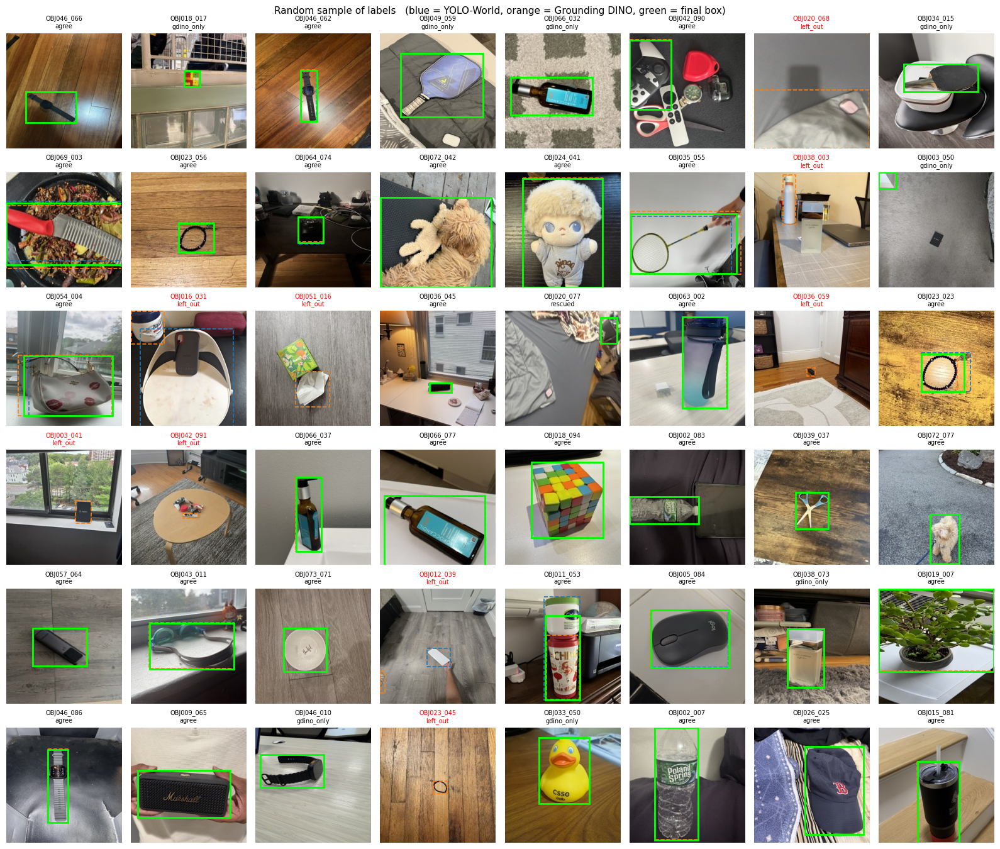

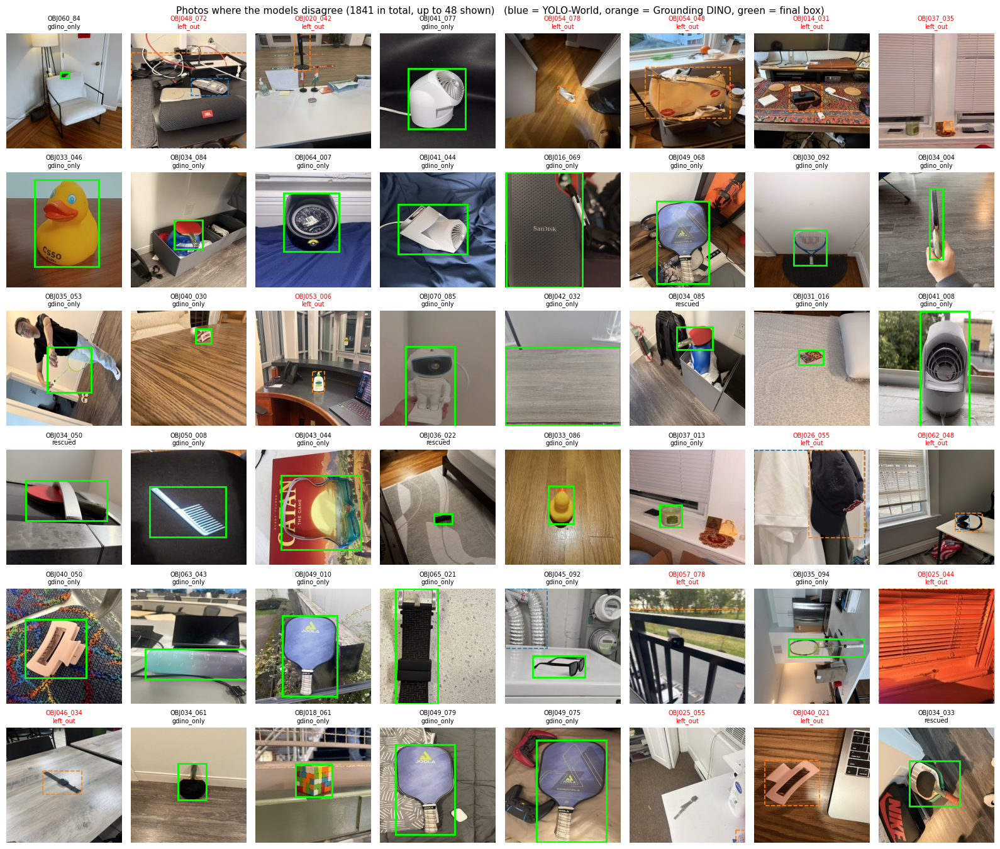

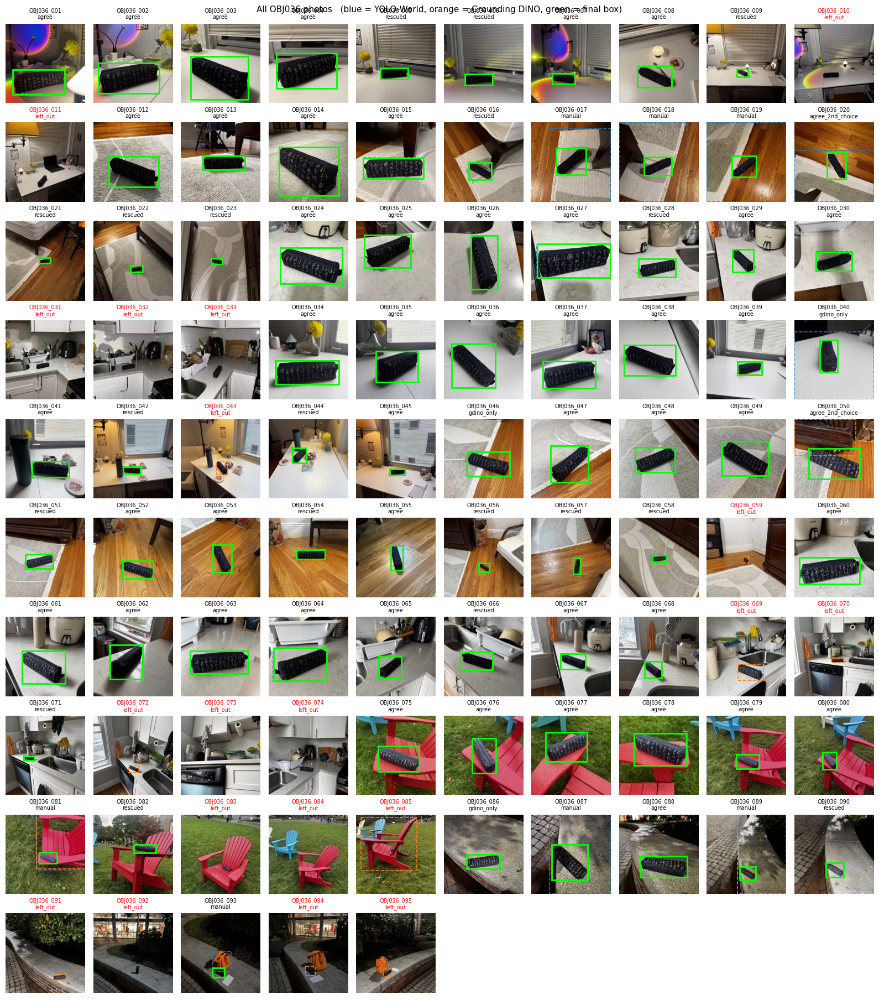

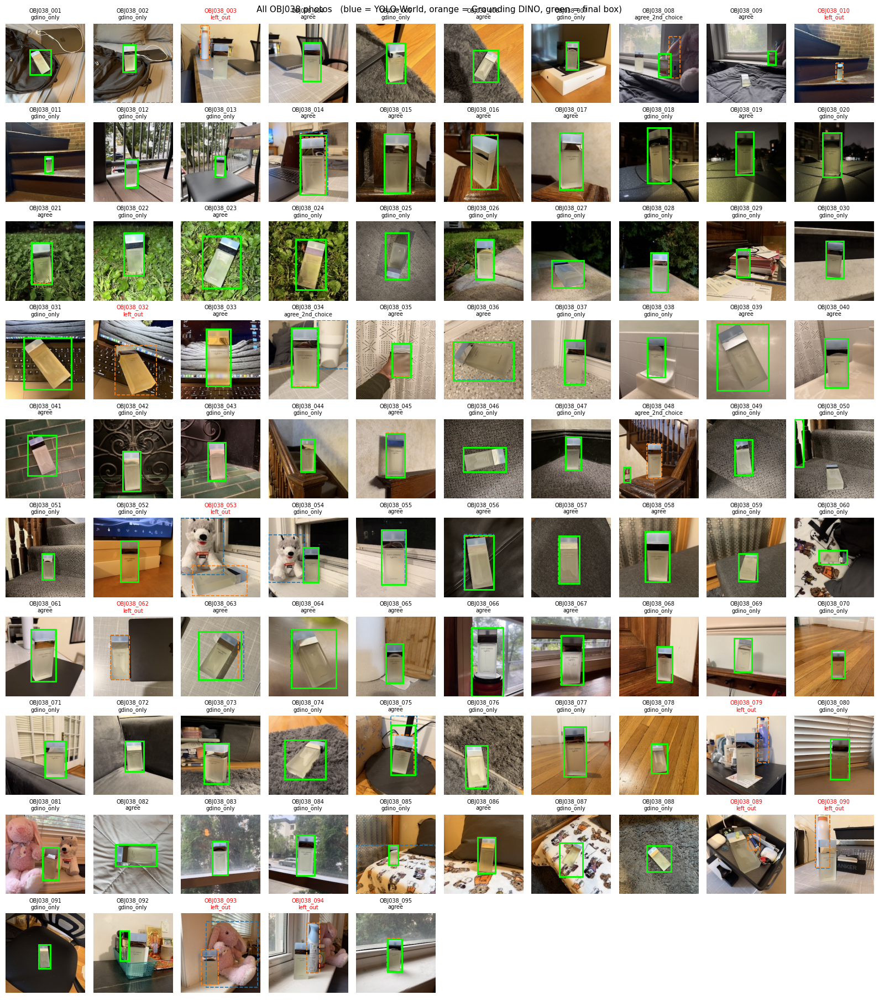

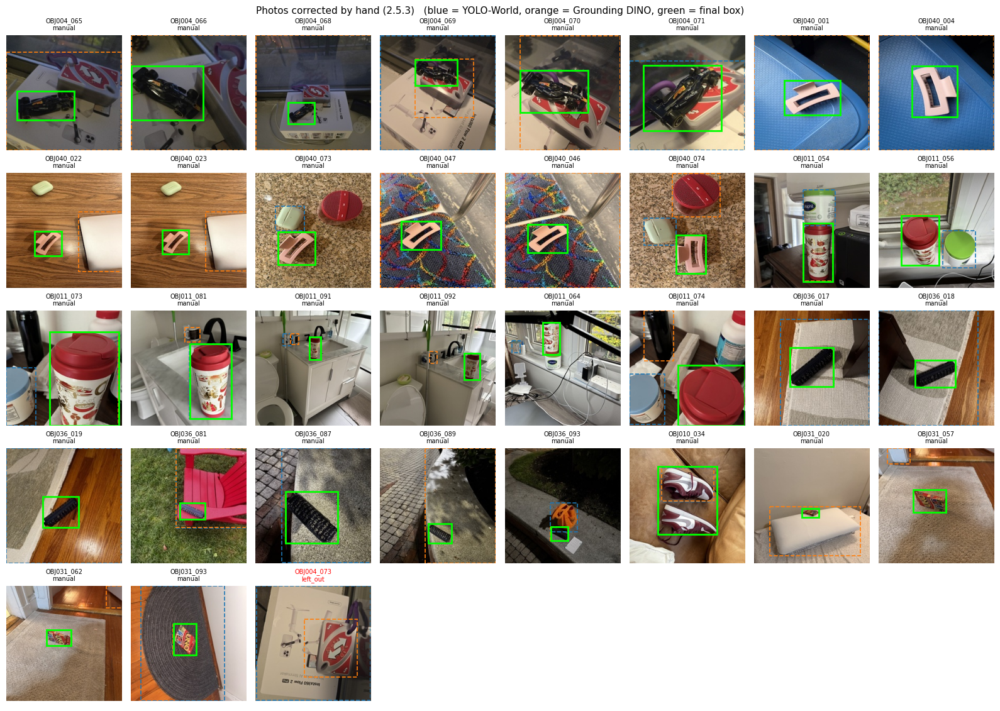

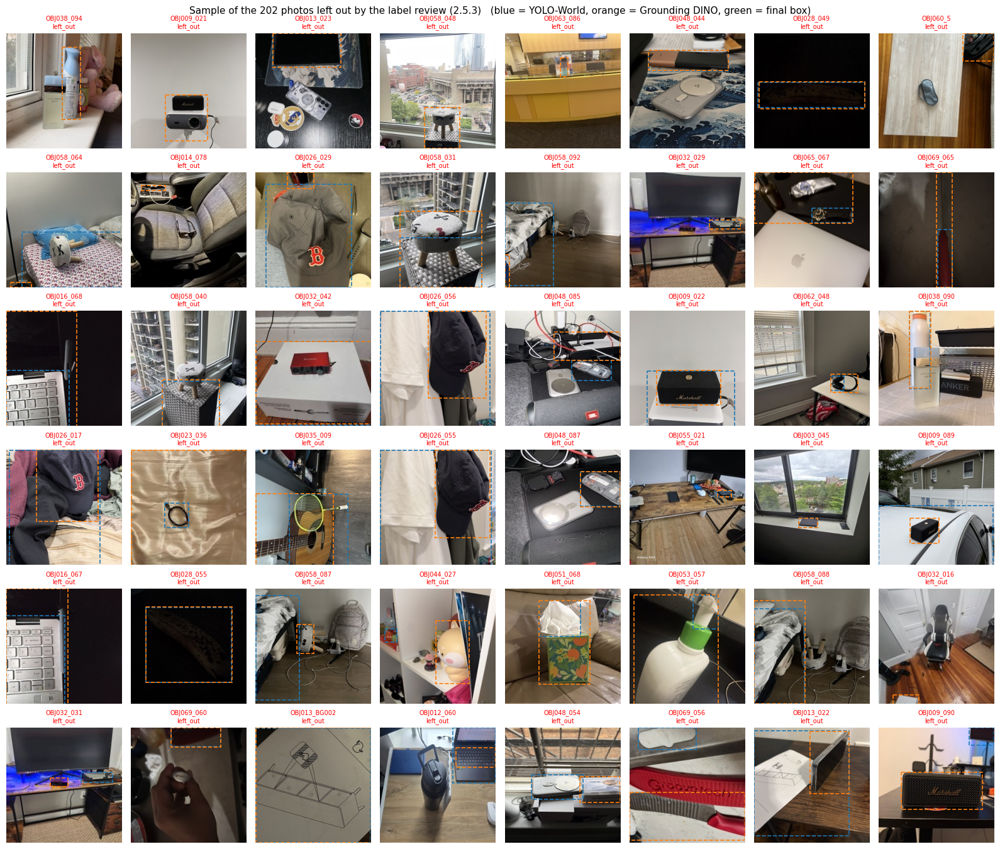

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches


def show_label_check(stems, title, fname, cols=8, size=2.0):
    stems = list(stems)
    if not stems:
        print("nothing to show:", title)
        return
    rows = (len(stems) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size * 1.15), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, stem in zip(axes.flat, stems):
        r = boxes.loc[stem]
        ax.imshow(Image.open(r.photo))
        for cands, color in [(yw_raw.get(stem, [])[:1], "tab:blue"), (gd_raw.get(stem, [])[:1], "tab:orange")]:
            for x1, y1, x2, y2, _ in cands:
                ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=color, lw=1.2, ls="--"))
        if r.used:
            ax.add_patch(patches.Rectangle((r.x1, r.y1), r.x2 - r.x1, r.y2 - r.y1, fill=False, ec="lime", lw=2))
        ax.set_title(f"{stem}\n{r.status}", fontsize=7, color="black" if r.used else "red")
    fig.suptitle(f"{title}   (blue = YOLO-World, orange = Grounding DINO, green = final box)", fontsize=11)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/{fname}", dpi=110)
    plt.show()


show_label_check(boxes.sample(min(48, len(boxes)), random_state=SEED).stem, "Random sample of labels", "label_check_random.png")
not_agree = boxes[~boxes.status.isin(["agree", "agree_2nd_choice"])]
show_label_check(not_agree.sample(min(48, len(not_agree)), random_state=SEED).stem if len(not_agree) else [],
                 f"Photos where the models disagree ({len(not_agree)} in total, up to 48 shown)", "label_check_disagree.png")
for fid in FOCUS_IDS:   # one figure per group object
    show_label_check(boxes[boxes.obj_id == fid].stem, f"All {fid} photos", f"label_check_{fid}.png", cols=10, size=1.6)
show_label_check(list(MANUAL_BOXES) + [s for s in MANUAL_EXCLUDE if s not in REVIEW_STEMS], "Photos corrected by hand (2.5.3)", "label_check_manual.png")
review = pd.Series(sorted(REVIEW_STEMS))
show_label_check(review.sample(min(48, len(review)), random_state=SEED), f"Sample of the {len(review)} photos left out by the label review (2.5.3)",
                 "label_check_review.png")

## 2.6 Multi-object grid images

> **Note (changed):** replaces the v1 generator (2–5 photos pasted on a background). Following the
> instructors' table:
>
> | Grid | Objects per image | Image size |
> |---|---|---|
> | 2×2 | 4 | 448 × 448 |
> | 3×3 | 9 | 672 × 672 |
> | 4×4 | 16 | 896 × 896 |
> | 5×4 | 20 | 1120 × 896 |
> | 5×5 | 25 | 1120 × 1120 |
>
> * **1,200 train** / 150 val / 150 test grids (final model; Milestone 2 used 800 train), with the five sizes in equal numbers in every split.
> * **Train grids use only train photos, val only val photos, test only test photos** (checked below).
> * Photos are dealt from a shuffled deck, so each photo is used about equally often and never twice in one grid.
> * **Augmentation (train only):** each tile is randomly flipped (as in v1, now with the box flipped too) and
>   gets random brightness, contrast and colour (±25%). YOLOv8 adds its own augmentation during training.
> * Labels are written in YOLO format (`class x_center y_center width height`, normalised by the grid size).
>   A zip copy of the grid dataset is saved to our Drive.

In [11]:
t0 = time.time()
YOLO_DIR = f"{WORK_DIR}/yolo_data"    # grid images + YOLO labels
lab = boxes[boxes.used]
BUILD_CFG = dict(grids=GRID_SIZES, n=N_GRIDS, seeds=GRID_SEEDS, classes=class_names,
                 labels=hashlib.md5(lab[["stem", "split", "x1", "y1", "x2", "y2"]].round(1).to_csv().encode()).hexdigest())


def augment_tile(im, box, rng):
    if rng.random() < 0.5:   # horizontal flip, box flipped with it
        im = ImageOps.mirror(im)
        box = [TILE - box[2], box[1], TILE - box[0], box[3]]
    for enhance in (ImageEnhance.Brightness, ImageEnhance.Contrast, ImageEnhance.Color):
        im = enhance(im).enhance(rng.uniform(0.75, 1.25))
    return im, box


def make_grid(stems, cols, rows, rng=None):
    canvas = Image.new("RGB", (cols * TILE, rows * TILE))
    objs = []
    for k, stem in enumerate(stems):
        r = lab.loc[stem]
        im, box = Image.open(r.photo).convert("RGB"), [r.x1, r.y1, r.x2, r.y2]
        if rng is not None:
            im, box = augment_tile(im, box, rng)
        ox, oy = (k % cols) * TILE, (k // cols) * TILE
        canvas.paste(im, (ox, oy))
        objs.append((class_names.index(r.obj_id), box[0] + ox, box[1] + oy, box[2] + ox, box[3] + oy))
    return canvas, objs


def make_split(name, n_images, seed):
    rng = np.random.default_rng(seed)
    img_dir, lbl_dir = f"{YOLO_DIR}/images/{name}", f"{YOLO_DIR}/labels/{name}"
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)
    pool, deck, manifest = list(lab.stem[lab.split == name]), [], []
    for k in range(n_images):
        cols, rows = GRID_SIZES[k % len(GRID_SIZES)]
        need = cols * rows
        assert len(pool) >= need, f"{name}: only {len(pool)} photos for a {cols}x{rows} grid"
        if len(deck) < need:
            deck += [pool[i] for i in rng.permutation(len(pool))]
        stems, later = [], []
        while len(stems) < need:   # never the same photo twice in one grid
            s = deck.pop(0)
            (later if s in stems else stems).append(s)
        deck = later + deck
        img, objs = make_grid(stems, cols, rows, rng if name == "train" else None)
        W, H = img.size
        fname = f"{name}_{k:05d}_{cols}x{rows}"
        img.save(f"{img_dir}/{fname}.jpg", quality=95)
        with open(f"{lbl_dir}/{fname}.txt", "w") as f:
            f.write("".join(f"{c} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}\n"
                            for c, x1, y1, x2, y2 in objs))
        manifest.append(dict(grid=fname, split=name, size=f"{cols}x{rows}", width=W, height=H, n_objects=need, stems=";".join(stems)))
    print(f"{name}: {n_images} images created")
    return manifest


def write_yaml(path, val):
    with open(path, "w") as f:
        f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: {val}\ntest: images/test\nnames:\n")
        for i, n in enumerate(class_names):
            f.write(f"  {i}: {n}\n")


cfg_file = f"{YOLO_DIR}/build_config.json"
if os.path.exists(cfg_file) and json.load(open(cfg_file)) == json.loads(json.dumps(BUILD_CFG)):
    print("grid images already built")
else:
    shutil.rmtree(YOLO_DIR, ignore_errors=True)
    manifest = []
    for name in ["train", "val", "test"]:
        manifest += make_split(name, N_GRIDS[name], GRID_SEEDS[name])
    man = pd.DataFrame(manifest)
    man.to_csv(f"{YOLO_DIR}/grids_manifest.csv", index=False)
    write_yaml(f"{YOLO_DIR}/data.yaml", "images/val")   # settings file that YOLOv8 reads
    for size in man["size"].unique():   # one test list per grid size, for the per-size results
        with open(f"{YOLO_DIR}/test_{size}.txt", "w") as f:
            f.write("".join(f"{YOLO_DIR}/images/test/{g}.jpg\n" for g in man.grid[(man.split == "test") & (man["size"] == size)]))
        write_yaml(f"{YOLO_DIR}/data_test_{size}.yaml", f"test_{size}.txt")
    json.dump(BUILD_CFG, open(cfg_file, "w"))
    shutil.make_archive(f"{OUT_DIR}/grid_dataset", "zip", YOLO_DIR)   # keep a copy in our own Drive
man = pd.read_csv(f"{YOLO_DIR}/grids_manifest.csv")

used = {s: set(";".join(man.stems[man.split == s]).split(";")) for s in ["train", "val", "test"]}
assert not (used["train"] & used["val" ] or used["train"] & used["test"] or used["val"] & used["test"])
print("check passed: train, val and test grids use different photos")
display(man.groupby(["size", "split"]).agg(images=("grid", "count"), objects=("n_objects", "sum")).unstack())
print(open(f"{YOLO_DIR}/labels/train/{man.grid[0]}.txt").read())
TIMES["grids"] = (time.time() - t0) / 60

train: 1200 images created
val: 150 images created
test: 150 images created
check passed: train, val and test grids use different photos


images           objects           
split   test train val    test train  val
size                                     
2x2       30   240  30     120   960  120
3x3       30   240  30     270  2160  270
4x4       30   240  30     480  3840  480
5x4       30   240  30     600  4800  600
5x5       30   240  30     750  6000  750

18 0.249944 0.275279 0.499888 0.449219
54 0.741239 0.262779 0.154353 0.164844
69 0.240123 0.775279 0.215067 0.267969
30 0.684096 0.738504 0.090737 0.099554



### 2.6.1 Example grid images with their labels

> **Note (changed):** same idea as v1's `show_with_boxes`. It now reads the image size from the file,
> because grids have five different sizes. One example per grid size.

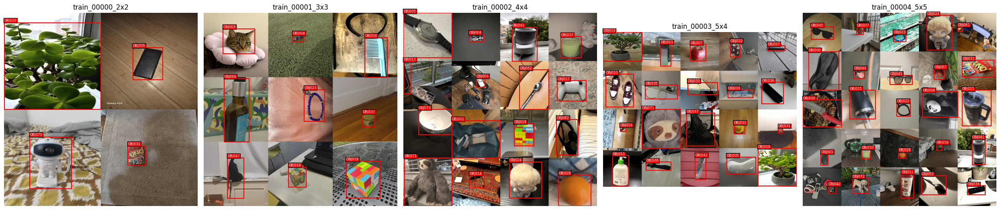

In [12]:
def grid_path(name):
    return f"{YOLO_DIR}/images/{name.split('_')[0]}/{name}.jpg"


def read_gt(img_path):
    # YOLO label file -> list of (class, x1, y1, x2, y2) in pixels
    W, H = Image.open(img_path).size
    out = []
    for line in open(img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"):
        c, cx, cy, w, h = map(float, line.split())
        out.append((int(c), (cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H))
    return out


def show_with_boxes(name, ax):
    path = grid_path(name)
    ax.imshow(Image.open(path))
    for c, x1, y1, x2, y2 in read_gt(path):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=1.5))
        ax.text(x1, y1 - 3, class_names[c], color="white", fontsize=6, bbox=dict(facecolor="red", pad=1))
    ax.axis("off")
    ax.set_title(name)


examples = [man.grid[(man.split == "train") & (man["size"] == f"{c}x{r}")].iloc[0] for c, r in GRID_SIZES]
fig, axes = plt.subplots(1, len(examples), figsize=(5 * len(examples), 5.4))
for ax, name in zip(np.atleast_1d(axes), examples):
    show_with_boxes(name, ax)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/grid_examples.png", dpi=110)
plt.show()

## 2.7 Train the final YOLOv8s model (transfer learning)

> **Note:** same model family as Milestone 2. **YOLOv8s pretrained on COCO** (11 M parameters) is fine-tuned on
> our grids, and its detection head is replaced for our 73 Object IDs. Final settings:
> * `imgsz=1120` (instructor tip). At 640, a 5×5 grid would be shrunk and each object would be only ~128 px wide.
> * `batch=8` (instructor tip for Colab; lower it if the GPU runs out of memory).
> * Up to 60 epochs, early stopping after 15 epochs without improvement. The run before the label fixes used all 60 epochs (56.6 min on a T4).
> * Grid images are cached on the Colab disk (`cache="disk"`) to speed up training. Caching them in RAM (4.5 GB)
>   ran out of Colab's system RAM and killed a dataloader worker.
> * Checkpoints are written to Drive after every epoch. If Colab disconnects, *Run all* again and training **resumes**
>   from `last.pt`.
> * If the session stops after the last epoch (the v2 run ran out of RAM during Ultralytics' final validation), a re-run
>   sees that `last.pt` is marked as finished and only writes `done.json`, instead of trying to resume.
> * The best epoch is chosen on the **validation** grids. The test grids are only used for the final results.

In [13]:
from ultralytics import YOLO

t0 = time.time()
RUN_DIR = f"{OUT_DIR}/runs/{RUN_NAME}"
LAST, BEST, DONE = f"{RUN_DIR}/weights/last.pt", f"{RUN_DIR}/weights/best.pt", f"{RUN_DIR}/done.json"
CACHE = "disk" if GPU else False   # "ram" ran out of Colab's ~12.7 GB RAM (4.5 GB of grids + dataloader workers)


def finished(path):   # Ultralytics sets epoch = -1 when it strips the optimizer at the end of training
    return torch.load(path, map_location="cpu", weights_only=False).get("epoch", 0) == -1


if os.path.exists(DONE):
    print("training already finished:", json.load(open(DONE)))
else:
    if os.path.exists(LAST) and finished(LAST):
        print("training finished, but done.json was not written (the session stopped after the last epoch)")
    elif os.path.exists(LAST):
        print("resuming from", LAST)
        try:
            YOLO(LAST).train(resume=True, cache=CACHE)   # cache may be changed on resume
        except AssertionError as e:   # last.pt belongs to a finished run
            print(e)
    else:
        model = YOLO(DET_WEIGHTS)   # small YOLOv8 model, pretrained on COCO
        results = model.train(
            data=f"{YOLO_DIR}/data.yaml",
            epochs=EPOCHS,
            imgsz=IMGSZ,
            batch=BATCH,
            patience=PATIENCE,    # stop early if validation results stop improving for 15 epochs
            seed=SEED,
            cache=CACHE,
            device=DEVICE,
            project=f"{OUT_DIR}/runs",
            name=RUN_NAME,
            exist_ok=True,
        )
    res = pd.read_csv(f"{RUN_DIR}/results.csv")
    res.columns = res.columns.str.strip()
    json.dump(dict(epochs_run=len(res), train_min=round(float(res["time"].iloc[-1]) / 60, 1) if "time" in res else None,
                   best_val_mAP50=round(float(res["metrics/mAP50(B)"].max()), 4)), open(DONE, "w"))
    print(json.load(open(DONE)))
TIMES["train"] = (time.time() - t0) / 60

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

## 2.8 Training curves and validation confusion matrix

> **Note (new):** Ultralytics already saves these figures in the run folder. The v1 report said they did not
> exist, but they did. Here they are shown and copied to `milestone3_v2/figures/` for the report.

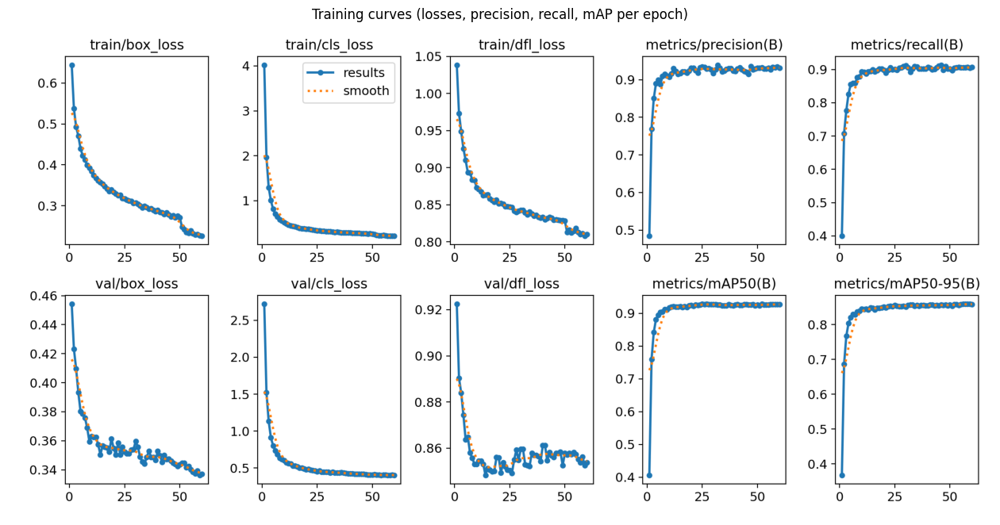

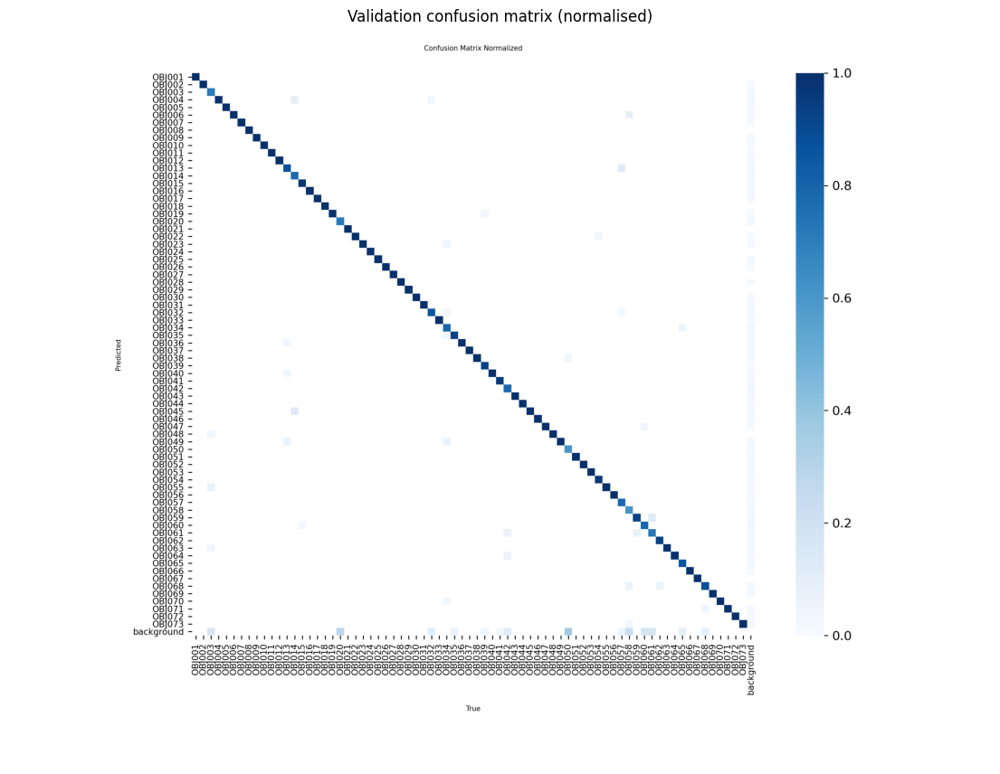

In [14]:
for fname, title in [("results.png", "Training curves (losses, precision, recall, mAP per epoch)"),
                     ("confusion_matrix_normalized.png", "Validation confusion matrix (normalised)")]:
    path = f"{RUN_DIR}/{fname}"
    if os.path.exists(path):
        shutil.copy(path, f"{OUT_DIR}/figures/train_{fname}")
        plt.figure(figsize=(16, 9) if fname == "results.png" else (14, 12))
        plt.imshow(plt.imread(path)); plt.axis("off"); plt.title(title)
        plt.show()
    else:
        print("not found:", path)

---
# Part 3 — Milestone 3: Final model (YOLOv8s): results, error analysis and live demo

The YOLOv8s model trained in 2.7 is our **final model**. Here it is evaluated once on the 150 held-out test grids
(2,220 objects), its errors are analysed, and 3.4 runs it on new images for the live demo.

| Item | Final model |
|---|---|
| Model | **YOLOv8s**, pretrained on COCO, fine-tuned on our grids (11.2 M parameters) |
| Input size | `imgsz=1120` (448 for a single 224 × 224 photo in the demo) |
| Training data | 1,200 train / 150 val / 150 test grid images (2×2 to 5×5), built from 6,395 single photos with boxes (label review: 22 boxes corrected, 203 photos left out, see 2.5.3) |
| Training | 60 epochs, batch 8, patience 15, T4 GPU; best epoch chosen on validation |
| **Test results** | **See 3.1.** Before the label fixes: precision 0.919 · recall 0.883 · mAP@0.5 0.912 · mAP@0.5:0.95 0.856 |
| Before vs after the label fixes | 3.1.1: the three final models scored on the same corrected test labels |
| Test at confidence 0.5 | See 3.2.1. Before the label fixes: 1,958 of 2,220 objects correct (ID right and IoU ≥ 0.5); 25 of 150 grids fully correct |
| Single photos (demo task a) | 3.2.2: test photos with and without test-time augmentation |

> The numbers written in this table are from the run before the label fixes; the cell outputs below are the current ones.

## 3.1 Test results of the final model

> **Note:** the final model is evaluated once on the 150 test grids (2,220 objects), plus:
> * the same metrics **per grid size** (2×2 … 5×5),
> * the metrics **per Object ID**, with our group's objects (`FOCUS_IDS`: OBJ036 and OBJ038) and the 10 weakest Object IDs,
> * the test confusion matrix.
>
> Precision and recall from Ultralytics are measured at the confidence threshold with the best F1 score.
> Because the boxes surround the object instead of the whole photo, **mAP@0.5:0.95 is lower than mAP@0.5**
> (before the label fixes: 0.856 vs 0.912). In v1 the two values were identical.
> * 3.1.1 scores the earlier final models on the same corrected test labels, for a fair comparison.

In [15]:
t0 = time.time()
best_model = YOLO(BEST)
VAL_KW = dict(imgsz=IMGSZ, batch=BATCH, device=DEVICE, project=f"{OUT_DIR}/runs", exist_ok=True)

test_metrics = best_model.val(data=f"{YOLO_DIR}/data.yaml", split="test", name="test_eval", **VAL_KW)

print("\nTEST RESULTS")
print("Precision:", round(test_metrics.box.mp, 3))
print("Recall:", round(test_metrics.box.mr, 3))
print("mAP50:", round(test_metrics.box.map50, 3))
print("mAP50-95:", round(test_metrics.box.map, 3))

def box_metrics(m):
    return dict(precision=round(float(m.box.mp), 3), recall=round(float(m.box.mr), 3),
                mAP50=round(float(m.box.map50), 3), mAP50_95=round(float(m.box.map), 3))

rows = [dict(grid="all test grids", images=int((man.split == "test").sum()),
             objects=int(man.n_objects[man.split == "test"].sum()), **box_metrics(test_metrics))]
for c, r in GRID_SIZES:
    m = best_model.val(data=f"{YOLO_DIR}/data_test_{c}x{r}.yaml", split="val", name=f"test_{c}x{r}", plots=False, verbose=False, **VAL_KW)
    sel = (man.split == "test") & (man["size"] == f"{c}x{r}")
    rows.append(dict(grid=f"{c}x{r} ({c * TILE}x{r * TILE})", images=int(sel.sum()), objects=int(man.n_objects[sel].sum()), **box_metrics(m)))
test_by_grid = pd.DataFrame(rows)
test_by_grid.to_csv(f"{OUT_DIR}/test_metrics_by_grid_size.csv", index=False)
print("\nTest results per grid size:")
display(test_by_grid)

per_class = pd.DataFrame([dict(obj_id=class_names[c], **dict(zip(["precision", "recall", "AP50", "AP50_95"],
                                                                map(float, test_metrics.box.class_result(i)))))
                          for i, c in enumerate(test_metrics.box.ap_class_index)]).round(3)
per_class.to_csv(f"{OUT_DIR}/test_metrics_per_object.csv", index=False)
print("Our group's objects:", ", ".join(FOCUS_IDS))
display(per_class[per_class.obj_id.isin(FOCUS_IDS)])
print("10 weakest Object IDs (AP50):")
display(per_class.sort_values("AP50").head(10))

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 89.2±34.9 MB/s, size: 346.2 KB)
val: Scanning /content/yolo_data/labels/test... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 504.9it/s 0.3s
val: New cache created: /content/yolo_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.1it/s 8.9s
                   all        150       2220      0.915      0.911      0.926       0.87
                OBJ001         30         30      0.981          1      0.995      0.995
                OBJ002         28         34      0.984          1      0.995      0.995
                OBJ003         29         30       0.83      0.667      0.661      0.645
                OBJ004         28         34      0.886          1      0.974    

,grid,images,objects,precision,recall,mAP50,mAP50_95
0,all test grids,150,2220,0.915,0.911,0.926,0.870
1,2x2 (448x448),30,120,0.836,0.840,0.916,0.836
2,3x3 (672x672),30,270,0.942,0.881,0.934,0.890
3,4x4 (896x896),30,480,0.935,0.899,0.931,0.887
4,5x4 (1120x896),30,600,0.910,0.896,0.917,0.871
5,5x5 (1120x1120),30,750,0.927,0.885,0.931,0.875


Our group's objects: OBJ036, OBJ038


,obj_id,precision,recall,AP50,AP50_95
35,OBJ036,0.966,1.000,0.995,0.995
37,OBJ038,0.809,0.833,0.815,0.742


10 weakest Object IDs (AP50):


,obj_id,precision,recall,AP50,AP50_95
2,OBJ003,0.830,0.667,0.661,0.645
41,OBJ042,0.840,0.600,0.709,0.696
67,OBJ068,0.683,0.580,0.722,0.604
50,OBJ051,0.735,0.778,0.749,0.589
13,OBJ014,0.849,0.656,0.762,0.659
31,OBJ032,0.758,0.729,0.768,0.744
64,OBJ065,0.808,0.735,0.770,0.638
12,OBJ013,0.848,0.720,0.773,0.748
11,OBJ012,0.765,0.778,0.781,0.734
37,OBJ038,0.809,0.833,0.815,0.742


### 3.1.1 Before vs after the label fixes

> **Note (new):** four test photos also had wrong labels (OBJ011_064, OBJ011_074, OBJ040_046 and OBJ040_074), so the test
> answer key changed too (and the OBJ010 pair boxes change it again). For a fair comparison, the earlier final models are scored again here on the **same corrected test
> labels**, next to the new model:
> 1. before any label fix (`milestone2_final/runs/final_yolov8s`),
> 2. after the 22 corrected boxes (`milestone3_v2/runs/final_yolov8s`),
> 3. after the full label review (`milestone3_v2/runs/final_yolov8s_v2`),
> 4. after the pencil case boxes and the sneaker pair boxes (`milestone3_v2/runs/final_yolov8s_v3`),
> 5. after the UNO boxes (this run, `milestone3_v2/runs/final_yolov8s_v4`).
>
> The second table shows the AP50 of every Object ID with photos corrected or left out in 2.5.3.

In [16]:
PREVIOUS_MODELS = {   # earlier final models, scored again on the same test labels
    "1. before label fixes": f"{MYDRIVE}/milestone2_final/runs/final_yolov8s/weights/best.pt",
    "2. 22 boxes corrected": f"{MYDRIVE}/milestone3_v2/runs/final_yolov8s/weights/best.pt",
    "3. label review": f"{MYDRIVE}/milestone3_v2/runs/final_yolov8s_v2/weights/best.pt",
    "4. pencil case + sneaker pairs": f"{MYDRIVE}/milestone3_v2/runs/final_yolov8s_v3/weights/best.pt",
}
FIXED_IDS = sorted({s.split("_")[0] for s in list(MANUAL_BOXES) + list(MANUAL_EXCLUDE)})
rows, ap50 = [], {}
for k, (name, path) in enumerate(PREVIOUS_MODELS.items()):
    if not os.path.exists(path):
        print("model not found, skipped:", path)
        continue
    m = YOLO(path).val(data=f"{YOLO_DIR}/data.yaml", split="test", name=f"test_eval_previous_{k + 1}",
                       plots=False, verbose=False, **VAL_KW)
    rows.append(dict(model=name, **box_metrics(m)))
    ap50[name] = {class_names[c]: round(float(m.box.class_result(i)[2]), 3) for i, c in enumerate(m.box.ap_class_index)}
rows.append(dict(model="5. UNO boxes (this run)", **box_metrics(test_metrics)))
ap50["5. UNO boxes (this run)"] = per_class.set_index("obj_id").AP50.to_dict()
before_after = pd.DataFrame(rows).set_index("model")
before_after.to_csv(f"{OUT_DIR}/test_before_after_label_fixes.csv")
print("All test grids, corrected test labels:")
display(before_after)
print("Object IDs with photos corrected or left out in 2.5.3 (AP50):")
display(pd.DataFrame(ap50).reindex(FIXED_IDS))

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2233.6±725.2 MB/s, size: 242.4 KB)
val: Scanning /content/yolo_data/labels/test... 150 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 1.8Kit/s 0.1s
val: New cache created: /content/yolo_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.5it/s 7.5s
                   all        150       2220      0.918      0.879      0.907      0.849
Speed: 2.5ms preprocess, 41.3ms inference, 0.0ms loss, 1.0ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3171.0±234.4 MB/s, size: 372.3 KB)
val: Scannin

,precision,recall,mAP50,mAP50_95
model,,,,
1. before label fixes,0.918,0.879,0.907,0.849
2. 22 boxes corrected,0.920,0.877,0.909,0.846
3. label review,0.917,0.885,0.903,0.844
4. pencil case + sneaker pairs,0.919,0.906,0.924,0.866
5. UNO boxes (this run),0.915,0.911,0.926,0.870


Object IDs with photos corrected or left out in 2.5.3 (AP50):


,1. before label fixes,2. 22 boxes corrected,3. label review,4. pencil case + sneaker pairs,5. UNO boxes (this run)
OBJ003,0.797,0.766,0.660,0.678,0.661
OBJ004,0.982,0.991,0.990,0.986,0.974
OBJ005,0.995,0.993,0.987,0.984,0.991
OBJ006,0.995,0.995,0.995,0.995,0.995
OBJ007,0.994,0.995,0.935,0.935,0.932
OBJ009,0.877,0.886,0.882,0.903,0.903
OBJ010,0.206,0.186,0.250,0.995,0.995
OBJ011,0.982,0.993,0.995,0.986,0.981
OBJ012,0.773,0.792,0.745,0.786,0.781
OBJ013,0.762,0.799,0.797,0.761,0.773


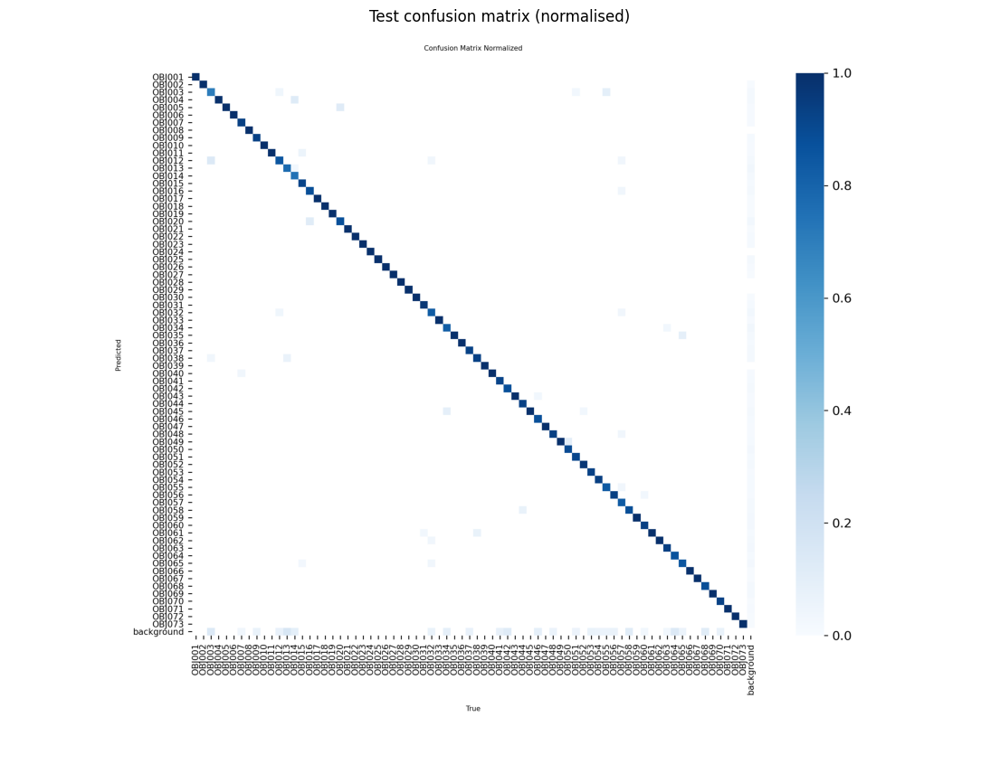

In [17]:
path = f"{OUT_DIR}/runs/test_eval/confusion_matrix_normalized.png"
if os.path.exists(path):
    shutil.copy(path, f"{OUT_DIR}/figures/test_confusion_matrix_normalized.png")
    plt.figure(figsize=(14, 12)); plt.imshow(plt.imread(path)); plt.axis("off"); plt.title("Test confusion matrix (normalised)")
    plt.show()

## 3.2 Detect, identify and locate the objects in an image

> **Note (changed):** `detect_objects` works as in v1. It prints every object's **ID, confidence and box**
> (x1, y1, x2, y2 in pixels) and now also the **grid row / column**. It also returns the table and can draw the
> prediction next to the true labels: white dashed = true box, green = correct detection, red = wrong ID or badly
> placed box. The thick box is `FOCUS_ID` (OBJ036, the first of our group's objects).
>
> `true_labels` prints the true objects of a grid, as in v1.

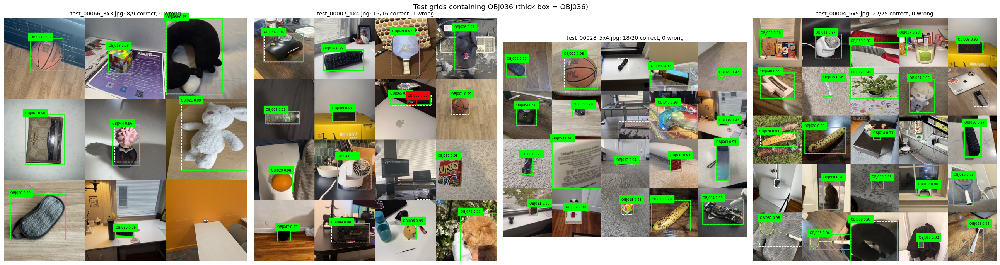

Image: test_00004_5x5.jpg | objects found: 22


,object_id,confidence,x1,y1,x2,y2,row,col
0,OBJ056,0.96,34,75,112,174,1,1
1,OBJ041,0.97,287,72,405,183,1,2
2,OBJ069,0.97,449,112,672,220,1,3
3,OBJ037,0.98,672,73,707,170,1,4
4,OBJ009,0.95,941,105,1056,164,1,5
5,OBJ040,0.99,31,251,189,369,2,1
6,OBJ025,0.96,322,279,366,361,2,2
7,OBJ019,0.98,449,255,669,369,2,3
8,OBJ024,0.98,719,282,835,434,2,4
9,OBJ028,0.93,26,528,202,591,3,1


TRUE objects in test_00004_5x5:


,object_id,x1,y1,x2,y2,row,col
0,OBJ056,34,76,112,174,1,1
1,OBJ041,288,72,405,183,1,2
2,OBJ069,448,110,672,223,1,3
3,OBJ037,672,74,706,170,1,4
4,OBJ009,941,105,1057,164,1,5
5,OBJ040,32,251,189,370,2,1
6,OBJ025,322,279,365,361,2,2
7,OBJ019,450,254,663,367,2,3
8,OBJ024,718,282,835,434,2,4
9,OBJ057,1014,330,1081,406,2,5


OBJ036 found at: [[3.0, 5.0, 972.0, 488.0, 1048.0, 640.0, 0.97]]


In [18]:
def detect_objects(image_path, conf=CONF, ax=None, verbose=True):
    result = best_model.predict(image_path, imgsz=IMGSZ, conf=conf, device=DEVICE, verbose=False)[0]
    rows = []
    for box in result.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        rows.append(dict(object_id=class_names[int(box.cls[0])], confidence=round(float(box.conf[0]), 2),
                         x1=round(x1), y1=round(y1), x2=round(x2), y2=round(y2),
                         row=int((y1 + y2) / 2 // TILE) + 1, col=int((x1 + x2) / 2 // TILE) + 1))
    det = pd.DataFrame(rows, columns=["object_id", "confidence", "x1", "y1", "x2", "y2", "row", "col"])
    det = det.sort_values(["row", "col"]).reset_index(drop=True)
    if verbose:
        print(f"Image: {os.path.basename(image_path)} | objects found: {len(det)}")
        display(det)
    if ax is not None:
        gt = read_gt(image_path) if "/images/" in image_path else None
        ax.imshow(Image.open(image_path)); ax.axis("off")
        for c, x1, y1, x2, y2 in gt or []:
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="white", lw=1, ls="--"))
        n_ok = 0
        for d in det.itertuples():
            ok = gt is None or any(class_names[c] == d.object_id and iou([d.x1, d.y1, d.x2, d.y2], b) >= 0.5 for c, *b in gt)
            n_ok += ok
            color = "lime" if ok else "red"
            ax.add_patch(patches.Rectangle((d.x1, d.y1), d.x2 - d.x1, d.y2 - d.y1, fill=False, ec=color,
                                           lw=3 if d.object_id == FOCUS_ID else 1.2))
            ax.text(d.x1, d.y1, f"{d.object_id} {d.confidence:.2f}", fontsize=6, color="black", backgroundcolor=color, va="bottom")
        if gt is not None:
            ax.set_title(f"{os.path.basename(image_path)}: {n_ok}/{len(gt)} correct, {len(det) - n_ok} wrong", fontsize=10)
    return det


def true_labels(name):
    print(f"TRUE objects in {name}:")
    gt = pd.DataFrame([dict(object_id=class_names[c], x1=round(x1), y1=round(y1), x2=round(x2), y2=round(y2),
                            row=int((y1 + y2) / 2 // TILE) + 1, col=int((x1 + x2) / 2 // TILE) + 1)
                       for c, x1, y1, x2, y2 in read_gt(grid_path(name))])
    display(gt.sort_values(["row", "col"]).reset_index(drop=True))


# example: test grids that contain OBJ036, one per grid size
focus_stems = set(lab.stem[lab.obj_id == FOCUS_ID])
test_grids = man[man.split == "test"]
has_focus = test_grids[test_grids.stems.apply(lambda s: bool(focus_stems & set(s.split(";"))))]
picks = [has_focus.grid[has_focus["size"] == f"{c}x{r}"].iloc[0] for c, r in GRID_SIZES if (has_focus["size"] == f"{c}x{r}").any()]
picks = picks[-4:] if picks else list(test_grids.grid[:4])
fig, axes = plt.subplots(1, len(picks), figsize=(6.5 * len(picks), 7))
for ax, name in zip(np.atleast_1d(axes), picks):
    detect_objects(grid_path(name), ax=ax, verbose=False)
plt.suptitle(f"Test grids containing {FOCUS_ID} (thick box = {FOCUS_ID})", fontsize=13)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/example_detections.png", dpi=120)
plt.show()

det = detect_objects(grid_path(picks[-1]))
true_labels(picks[-1])
print(f"{FOCUS_ID} found at:", det.loc[det.object_id == FOCUS_ID, ["row", "col", "x1", "y1", "x2", "y2", "confidence"]].values.tolist())

### 3.2.1 All test grids at confidence 0.5, and error analysis

> **Note (new):** v1 showed one example. This cell runs `detect_objects` on **every test grid** at the
> same threshold (0.5). A detection is correct when the Object ID is right and the box overlaps the true box with
> IoU ≥ 0.5. It reports:
> * correct / wrong / missed objects and the number of grids where **every** object was found with nothing extra,
>   per grid size,
> * which Object IDs are missed most, and which IDs are confused with which,
> * a figure with examples of missed objects, as input for the report's error analysis.

Test grids at confidence 0.5:


,images,objects,correct,wrong_or_extra,missed,grids_all_correct,precision,recall
size,,,,,,,,
2x2,30,120,102,8,18,15,0.927,0.850
3x3,30,270,244,20,26,8,0.924,0.904
4x4,30,480,437,30,43,4,0.936,0.910
5x4,30,600,536,35,64,2,0.939,0.893
5x5,30,750,671,46,79,1,0.936,0.895
all,150,2220,1990,139,230,30,0.935,0.896


Object IDs with the most missed or wrongly identified test objects:


,errors
true_id,
OBJ068,13
OBJ014,13
OBJ013,11
OBJ051,11
OBJ065,11
OBJ003,10
OBJ042,10
OBJ057,9
OBJ058,8


Most frequent confusions (true -> predicted):


,,count
true_id,predicted_id,
OBJ016,OBJ020,4
OBJ055,OBJ003,3
OBJ014,OBJ004,2
OBJ012,OBJ009,1
OBJ013,OBJ038,1
OBJ020,OBJ005,1
OBJ034,OBJ045,1
OBJ037,OBJ018,1
OBJ050,OBJ049,1


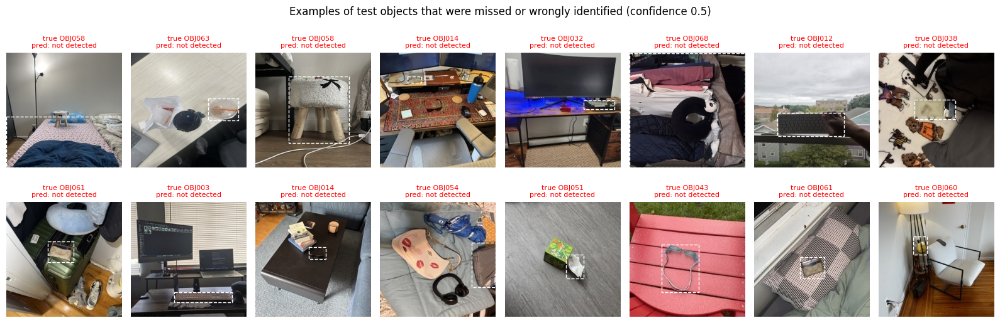

In [19]:
def match(pred, gt, conf):
    # greedy by confidence: correct if same Object ID and IoU >= 0.5 with a true box that is not matched yet
    cls, cf, xy = pred
    keep = [i for i in np.argsort(cf)[::-1] if cf[i] >= conf]
    taken, ok = set(), []
    for i in keep:
        best, bj = 0.5, None
        for j, (c, *b) in enumerate(gt):
            if j not in taken and c == cls[i] and iou(xy[i], b) >= best:
                best, bj = iou(xy[i], b), j
        if bj is not None:
            taken.add(bj)
        ok.append(bj is not None)
    return keep, ok, taken


test_paths = [grid_path(g) for g in test_grids.grid]
preds = {}
for i in range(0, len(test_paths), 8):   # 8 grids at a time (1120 px) to stay within GPU memory
    batch = test_paths[i:i + 8]
    for p, r in zip(batch, best_model.predict(batch, imgsz=IMGSZ, conf=CONF, device=DEVICE, verbose=False)):
        preds[p] = (r.boxes.cls.int().tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())

per_img, errors = [], []
for p, pred in preds.items():
    gt = read_gt(p)
    keep, ok, taken = match(pred, gt, CONF)
    per_img.append(dict(size=os.path.basename(p)[:-4].split("_")[-1], objects=len(gt), correct=sum(ok),
                        wrong_or_extra=len(ok) - sum(ok), missed=len(gt) - len(taken)))
    cls, cf, xy = pred
    for j, (c, *b) in enumerate(gt):
        if j not in taken:
            o, i = max(((iou(xy[i], b), i) for i in keep), default=(0, None))
            errors.append(dict(path=p, box=b, true_id=class_names[c],
                               predicted=f"{class_names[cls[i]]} ({cf[i]:.2f})" if o >= 0.5 else "not detected",
                               predicted_id=class_names[cls[i]] if o >= 0.5 else None))
per_img = pd.DataFrame(per_img)
per_img["all_correct"] = (per_img.wrong_or_extra == 0) & (per_img.missed == 0)
by_size = per_img.groupby("size").agg(images=("objects", "size"), objects=("objects", "sum"), correct=("correct", "sum"),
                                      wrong_or_extra=("wrong_or_extra", "sum"), missed=("missed", "sum"),
                                      grids_all_correct=("all_correct", "sum"))
by_size.loc["all"] = by_size.sum()
by_size["precision"] = (by_size.correct / (by_size.correct + by_size.wrong_or_extra).clip(lower=1)).round(3)
by_size["recall"] = (by_size.correct / by_size.objects).round(3)
by_size.to_csv(f"{OUT_DIR}/test_detection_at_conf{CONF}.csv")
print(f"Test grids at confidence {CONF}:")
display(by_size)

errors = pd.DataFrame(errors, columns=["path", "box", "true_id", "predicted", "predicted_id"])
print("Object IDs with the most missed or wrongly identified test objects:")
display(errors.true_id.value_counts().head(10).rename("errors"))
print("Most frequent confusions (true -> predicted):")
display(errors.dropna(subset=["predicted_id"]).groupby(["true_id", "predicted_id"]).size().sort_values(ascending=False).head(10).rename("count"))

n = min(16, len(errors))
if n:
    show = errors.sample(n, random_state=SEED)
    fig, axes = plt.subplots((n + 7) // 8, 8, figsize=(16, 2.8 * ((n + 7) // 8)), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, e in zip(axes.flat, show.itertuples()):
        x1, y1, x2, y2 = e.box
        col, row = int((x1 + x2) / 2 // TILE), int((y1 + y2) / 2 // TILE)
        ax.imshow(Image.open(e.path).crop((col * TILE, row * TILE, (col + 1) * TILE, (row + 1) * TILE)))
        ax.add_patch(patches.Rectangle((x1 - col * TILE, y1 - row * TILE), x2 - x1, y2 - y1, fill=False, ec="white", ls="--"))
        ax.set_title(f"true {e.true_id}\npred: {e.predicted}", fontsize=8, color="red")
    plt.suptitle(f"Examples of test objects that were missed or wrongly identified (confidence {CONF})")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/test_errors.png", dpi=110)
    plt.show()
TIMES["evaluate"] = (time.time() - t0) / 60

### 3.2.2 Single photos: with and without test-time augmentation (TTA)

> **Note (new):** demo task (a) is one 224 × 224 photo. With **test-time augmentation** (`augment=True`), YOLOv8 also
> looks at a flipped and rescaled copy of the photo and merges the results. This can raise the confidence (a training
> photo of OBJ052 went from 0.87 to 0.94 with the previous model), but it can also add wrong boxes. This cell runs the
> final model on every **test** photo (never used for training) at `imgsz=448`, with and without TTA:
> * **top-1 correct**: the most confident box has the right Object ID,
> * **correct at conf**: the same, with a confidence of at least 0.5 (what the demo shows),
> * **photos with a wrong box**: at least one box of another Object ID with a confidence of at least 0.5,
> * **mean confidence** of the most confident box when it is correct.
>
> The demo (3.4) uses TTA for single photos if it finds **more** photos correctly (*correct at conf*) than it adds photos
> with a wrong box. First run: with TTA, 39 more of the 985 test photos were correct and 9 more had a wrong box, so TTA is
> used. The decision is saved to `milestone3_v2/single_photo_tta.json`, which 3.4 reads.

In [20]:
t0 = time.time()
single = lab[lab.split == "test"]   # 224 x 224 test photos with a box, never used for training
tta_rows = []
for tta in (False, True):
    top1, ok_conf, wrong, conf_ok = 0, 0, 0, []
    for i in range(0, len(single), 32):
        chunk = single.iloc[i:i + 32]
        res = best_model.predict(list(chunk.photo), imgsz=SINGLE_IMGSZ, conf=0.05, augment=tta, device=DEVICE, verbose=False)
        for r, oid in zip(res, chunk.obj_id):
            ids, cf = [class_names[int(c)] for c in r.boxes.cls.tolist()], r.boxes.conf.tolist()
            if ids and ids[int(np.argmax(cf))] == oid:
                top1 += 1
                ok_conf += max(cf) >= CONF
                conf_ok.append(max(cf))
            wrong += any(p != oid and c >= CONF for p, c in zip(ids, cf))
    tta_rows.append(dict(photos=len(single), top1_correct=round(top1 / len(single), 4),
                         correct_at_conf=round(ok_conf / len(single), 4), photos_with_wrong_box=wrong,
                         mean_conf_when_correct=round(float(np.mean(conf_ok)), 3)))
no_tta, with_tta = tta_rows
display(pd.DataFrame(tta_rows, index=["without TTA", "with TTA"]))
gain = round((with_tta["correct_at_conf"] - no_tta["correct_at_conf"]) * len(single))   # photos found correctly only with TTA
extra_wrong = with_tta["photos_with_wrong_box"] - no_tta["photos_with_wrong_box"]      # photos with a wrong box added by TTA
USE_TTA = bool(gain > extra_wrong)
print(f"TTA: {gain:+d} photos correct, {extra_wrong:+d} photos with a wrong box")
json.dump(dict(use_tta=USE_TTA, gain=gain, extra_wrong=extra_wrong, no_tta=no_tta, tta=with_tta),
          open(f"{OUT_DIR}/single_photo_tta.json", "w"), indent=1)
print("Use TTA for single photos in the demo (3.4):", USE_TTA)
TIMES["single_photo_tta"] = (time.time() - t0) / 60

,photos,top1_correct,correct_at_conf,photos_with_wrong_box,mean_conf_when_correct
without TTA,985,0.9523,0.9188,28,0.914
with TTA,985,0.9594,0.9492,47,0.951


TTA: +30 photos correct, +19 photos with a wrong box
Use TTA for single photos in the demo (3.4): True


### 3.2.3 Demo rule: the most confident box of each grid cell

> **Note (new):** in the live demo, five objects (swimming goggles, comb, purse, water tumbler, sneakers) were missed
> although the v2 model had found each of them with the right ID and box, only with a score of 0.18–0.32. A lower global
> threshold does not help: it finds these objects but adds about as many wrong boxes. A grid cell, however, always holds
> **one** object, so the demo keeps only the most confident box of each cell, if it is above a floor. This also removes
> extra boxes in a cell (e.g. a second box on the same object).
>
> The floor is chosen on the **validation** grids (best F1) and saved to `milestone3_v2/demo_conf.json` for 3.4. The test
> grids are shown for the report only and are not used to choose it.

In [21]:
def one_per_cell(pred, floor):   # each grid cell holds one object: keep its most confident box, if >= floor
    cls, cf, xy = pred
    best = {}
    for i, b in enumerate(xy):
        k = (int((b[0] + b[2]) / 2 // TILE), int((b[1] + b[3]) / 2 // TILE))
        if cf[i] >= floor and (k not in best or cf[i] > cf[best[k]]):
            best[k] = i
    keep = sorted(best.values())
    return [cls[i] for i in keep], [cf[i] for i in keep], [xy[i] for i in keep]


def predict_all(paths, conf):
    out = {}
    for i in range(0, len(paths), 8):   # 8 grids at a time (1120 px) to stay within GPU memory
        batch = paths[i:i + 8]
        for p, r in zip(batch, best_model.predict(batch, imgsz=IMGSZ, conf=conf, device=DEVICE, verbose=False)):
            out[p] = (r.boxes.cls.int().tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())
    return out


def counts(preds, floor=None):   # floor=None: every box of at least CONF (as in 3.2.1)
    n_obj = n_ok = n_det = 0
    for p, pred in preds.items():
        gt = read_gt(p)
        keep, ok, taken = match(pred, gt, CONF) if floor is None else match(one_per_cell(pred, floor), gt, 0)
        n_obj, n_ok, n_det = n_obj + len(gt), n_ok + sum(ok), n_det + len(ok)
    prec, rec = n_ok / max(n_det, 1), n_ok / n_obj
    return dict(correct=n_ok, wrong_or_extra=n_det - n_ok, missed=n_obj - n_ok, precision=round(prec, 3),
                recall=round(rec, 3), F1=round(2 * prec * rec / max(prec + rec, 1e-9), 4))


t0 = time.time()
val_preds = predict_all(sorted(glob.glob(f"{YOLO_DIR}/images/val/*.jpg")), 0.05)
sweep = pd.DataFrame([dict(rule=f"most confident box per cell, >= {f}", floor=f, **counts(val_preds, f))
                      for f in np.round(np.arange(0.05, 0.501, 0.05), 2)])
FLOOR = float(sweep.floor[sweep.F1.idxmax()])
print(f"Validation grids: best F1 with a floor of {FLOOR}")
display(pd.concat([pd.DataFrame([dict(rule=f"every box >= {CONF}", **counts(val_preds))]), sweep.drop(columns="floor")])
        .set_index("rule"))

test_preds = predict_all(test_paths, 0.05)
demo_test = {f"every box >= {CONF}": counts(test_preds), f"most confident box per cell, >= {FLOOR}": counts(test_preds, FLOOR)}
print("Test grids (report only, not used to choose the floor):")
display(pd.DataFrame(demo_test).T)
json.dump(dict(model=BEST, floor=FLOOR, test=demo_test), open(f"{OUT_DIR}/demo_conf.json", "w"), indent=1)
print("saved for the demo (3.4):", f"{OUT_DIR}/demo_conf.json")
TIMES["demo_rule"] = (time.time() - t0) / 60


Validation grids: best F1 with a floor of 0.05


,correct,wrong_or_extra,missed,precision,recall,F1
rule,,,,,,
every box >= 0.5,2013,125,207,0.942,0.907,0.9238
"most confident box per cell, >= 0.05",2055,136,165,0.938,0.926,0.9318
"most confident box per cell, >= 0.1",2047,129,173,0.941,0.922,0.9313
"most confident box per cell, >= 0.15",2037,123,183,0.943,0.918,0.9301
"most confident box per cell, >= 0.2",2034,120,186,0.944,0.916,0.9300
"most confident box per cell, >= 0.25",2033,115,187,0.946,0.916,0.9309
"most confident box per cell, >= 0.3",2026,114,194,0.947,0.913,0.9294
"most confident box per cell, >= 0.35",2018,109,202,0.949,0.909,0.9285
"most confident box per cell, >= 0.4",2016,105,204,0.950,0.908,0.9288


Test grids (report only, not used to choose the floor):


,correct,wrong_or_extra,missed,precision,recall,F1
every box >= 0.5,1990.0,139.0,230.0,0.935,0.896,0.9152
"most confident box per cell, >= 0.05",2025.0,166.0,195.0,0.924,0.912,0.9182


saved for the demo (3.4): /content/drive/MyDrive/milestone3_v2/demo_conf.json


## 3.3 Final model summary for the report

> **Note:** collects every number the instructors asked for: Object IDs, grid sizes, how the labels were made
> and checked, photos left out per Object ID, metrics, training details and timings. It is saved as
> `milestone3_v2/week2_summary.json`, with the label fixes (2.5.3), the before / after comparison (3.1.1) and the
> single-photo check (3.2.2). The final model is copied to `milestone3_v2/best_final_yolov8s_v2.pt`.

In [22]:
shutil.copy(BEST, f"{OUT_DIR}/best_{RUN_NAME}.pt")
TIMES["total_this_session"] = (time.time() - T_START) / 60
summary = dict(
    object_ids=f"{len(class_names)} IDs ({class_names[0]}–{class_names[-1]})",
    grid_sizes=[f"{c}x{r} ({c * TILE}x{r * TILE})" for c, r in GRID_SIZES],
    photos=dict(unique=len(photos),
                removed_before_split={k: int(v) for k, v in removed.reason.str.replace(r" of OBJ.*|:.*", "", regex=True).value_counts().items()},
                **{k: int(v) for k, v in photos.split.value_counts().items()}),
    labels=LABEL_STATS,
    left_out_per_object={k: int(v) for k, v in per_obj.left_out[per_obj.left_out > 0].items()},
    grids={s: int((man.split == s).sum()) for s in ["train", "val", "test"]},
    objects_in_grids={s: int(man.n_objects[man.split == s].sum()) for s in ["train", "val", "test"]},
    training=dict(model=DET_WEIGHTS, imgsz=IMGSZ, batch=BATCH, max_epochs=EPOCHS, patience=PATIENCE, **json.load(open(DONE))),
    test=test_by_grid.iloc[0][["precision", "recall", "mAP50", "mAP50_95"]].to_dict(),
    test_by_grid=test_by_grid.set_index("grid")[["precision", "recall", "mAP50", "mAP50_95"]].to_dict("index"),
    test_at_conf=dict(conf=CONF, **{k: (int(v) if k not in ("precision", "recall") else float(v)) for k, v in by_size.loc["all"].items()}),
    focus_objects=per_class[per_class.obj_id.isin(FOCUS_IDS)].to_dict("records"),
    label_fixes=dict(boxes=len(MANUAL_BOXES), excluded=len(MANUAL_EXCLUDE), review_excluded=len(REVIEW_STEMS), object_ids=FIXED_IDS),
    before_after_label_fixes=before_after.to_dict("index"),
    single_photo_tta=dict(use_tta=USE_TTA, gain=gain, extra_wrong=extra_wrong, no_tta=no_tta, tta=with_tta),
    demo_rule=json.load(open(f"{OUT_DIR}/demo_conf.json")),
    minutes={k: round(v, 1) for k, v in TIMES.items()},
)
json.dump(summary, open(f"{OUT_DIR}/week2_summary.json", "w"), indent=1, default=str)
print(json.dumps(summary, indent=1, default=str))

{
 "object_ids": "73 IDs (OBJ001\u2013OBJ073)",
 "grid_sizes": [
  "2x2 (448x448)",
  "3x3 (672x672)",
  "4x4 (896x896)",
  "5x4 (1120x896)",
  "5x5 (1120x1120)"
 ],
 "photos": {
  "unique": 6947,
  "removed_before_split": {
   "exact duplicate": 16,
   "excluded": 1
  },
  "train": 4862,
  "test": 1043,
  "val": 1042
 },
 "labels": {
  "photos": 6947,
  "used": 6395,
  "left_out": 552,
  "models_agree": 5106,
  "agree_pct": 73.5,
  "mean_iou_when_agree": 0.945,
  "status_counts": {
   "agree": 4642,
   "gdino_only": 1120,
   "left_out": 552,
   "agree_2nd_choice": 464,
   "rescued": 129,
   "manual": 34,
   "yoloworld_only": 6
  }
 },
 "left_out_per_object": {
  "OBJ003": 19,
  "OBJ004": 7,
  "OBJ005": 1,
  "OBJ006": 1,
  "OBJ007": 2,
  "OBJ009": 8,
  "OBJ012": 15,
  "OBJ013": 20,
  "OBJ014": 18,
  "OBJ016": 12,
  "OBJ017": 2,
  "OBJ020": 19,
  "OBJ023": 13,
  "OBJ025": 18,
  "OBJ026": 5,
  "OBJ028": 7,
  "OBJ029": 1,
  "OBJ030": 6,
  "OBJ031": 2,
  "OBJ032": 19,
  "OBJ033": 8,
  "OBJ

## 3.4 Live demo: run the final model on new images

> **Note (new):** a stand-alone cell for the live demo. It mounts Drive, loads the final weights
> (`milestone3_v2/runs/final_yolov8s_v4/weights/best.pt`, or the newest earlier version if v4 is not trained yet) and asks you to upload images
> (select all at once). Each grid cell (and each single photo) holds **one** object, so only the most confident box of
> each cell is shown if it is above the floor chosen in 3.2.3 (`milestone3_v2/demo_conf.json`; 0.5 if 3.2.3 was not run
> for this model). An image that is not a 224 px grid shows every box of at least 0.5.
> * **(a) Single object:** a photo of 336 px or smaller is treated as one 224 px photo and run at `imgsz=448`, with
>   test-time augmentation if 3.2.2 found that it helps (read from `milestone3_v2/single_photo_tta.json`).
> * **(b) Multi-object grid:** anything larger is run at `imgsz=1120`.
>
> For each image it shows the detections and a table with every object's **ID, name, confidence, box (x1, y1, x2, y2)
> and grid row / column**. The table is also saved as `<image name>_detections.csv`.
> This covers both demo tasks. The cell can run on its own after a restart, so the full notebook does not need to be re-run for the demo.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
model: /content/drive/MyDrive/milestone3_v2/runs/final_yolov8s_v4/weights/best.pt | floor for the most confident box of each cell: 0.05


Saving image (1).jpeg to image (1) (2).jpeg
Saving image.jpeg to image (3).jpeg
Saving test_00001_3x3.jpg to test_00001_3x3 (3).jpg
Saving TEST_E.jpg to TEST_E (2).jpg
Saving TEST_J.jpg to TEST_J (2).jpg
Saving test.jpg to test (2).jpg

image (1) (2).jpeg: 16 objects found


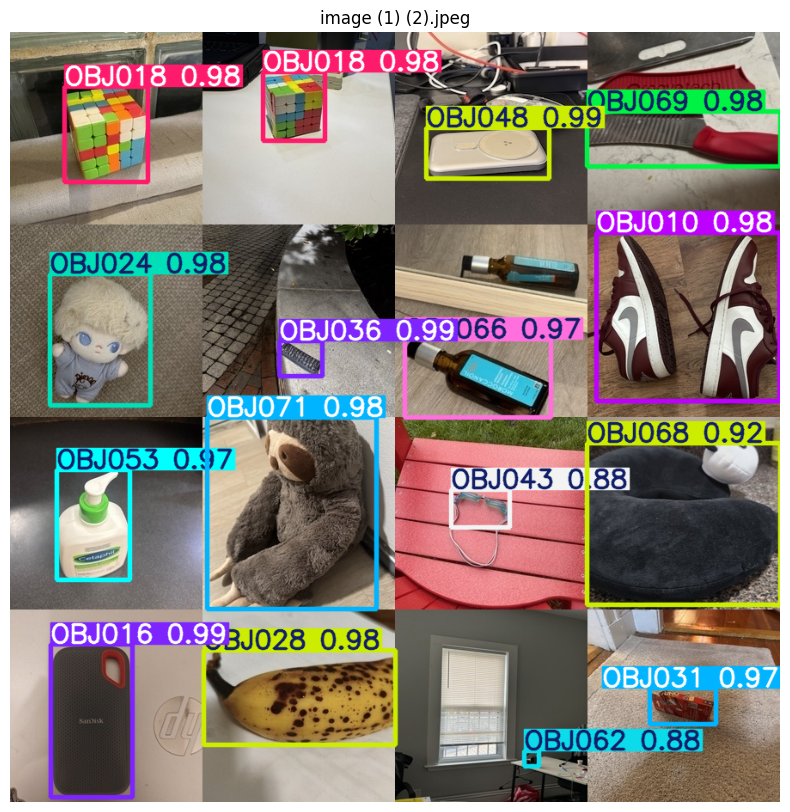

,object_id,object_name,confidence,x1,y1,x2,y2,row,col
0,OBJ018,Rubiks Cube,0.98,64,63,161,175,1,1
1,OBJ018,Rubiks Cube,0.98,294,47,366,127,1,2
2,OBJ048,Wireless Powerbank,0.99,485,111,627,171,1,3
3,OBJ069,Knife,0.98,672,92,896,157,1,4
4,OBJ024,Plush Doll,0.98,47,282,163,434,2,1
5,OBJ036,Pencil Case,0.99,313,360,363,400,2,2
6,OBJ066,Hair Oil,0.97,460,357,630,448,2,3
7,OBJ010,Nike Sneakers,0.98,682,233,896,430,2,4
8,OBJ053,Moisturizer,0.97,54,509,140,638,3,1
9,OBJ071,Sloth Plushie,0.98,230,448,427,672,3,2



image (3).jpeg: 25 objects found


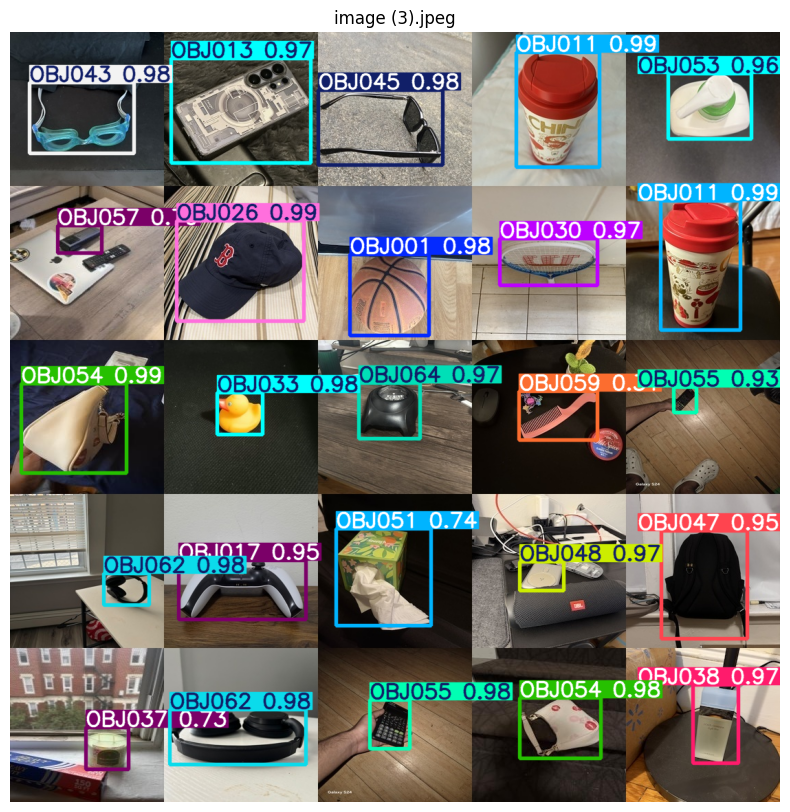

,object_id,object_name,confidence,x1,y1,x2,y2,row,col
0,OBJ043,Swimming Goggles,0.98,29,73,180,176,1,1
1,OBJ013,Mobile Phone,0.97,234,38,438,191,1,2
2,OBJ045,Wayfarer Sunglasses,0.98,449,84,629,194,1,3
3,OBJ011,Mug,0.99,736,30,857,196,1,4
4,OBJ053,Moisturizer,0.96,958,60,1078,156,1,5
5,OBJ057,Power Bank,0.79,70,282,134,322,2,1
6,OBJ026,Red Sox Cap,0.99,243,274,428,420,2,2
7,OBJ001,Basketball,0.98,494,323,610,441,2,3
8,OBJ030,Tennis Racket,0.97,712,300,855,368,2,4
9,OBJ011,Mug,0.99,947,245,1062,434,2,5



test_00001_3x3 (3).jpg: 9 objects found


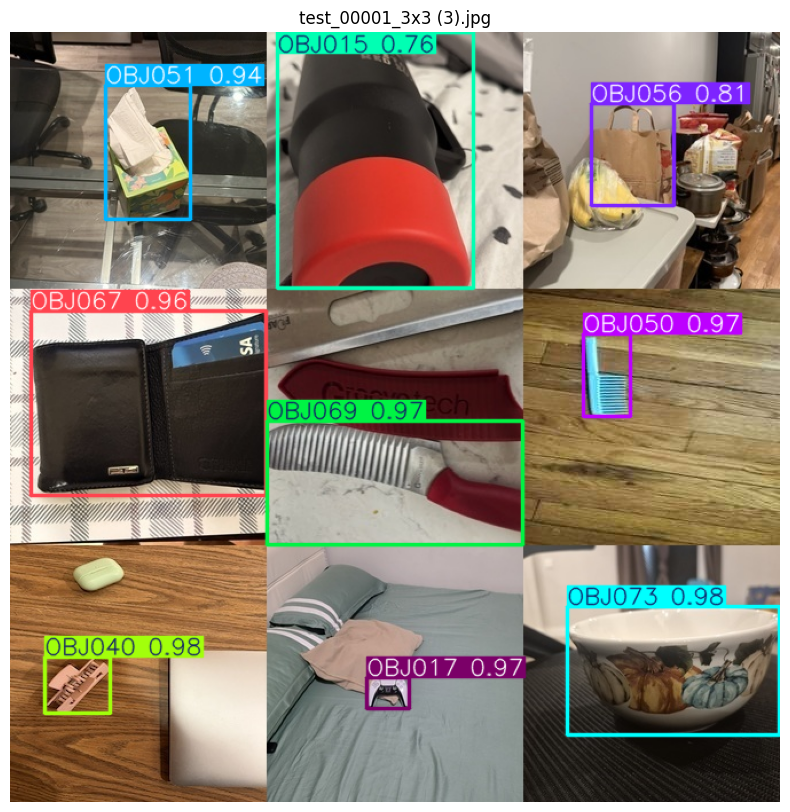

,object_id,object_name,confidence,x1,y1,x2,y2,row,col
0,OBJ051,Tissue,0.94,83,47,158,164,1,1
1,OBJ015,Water Tumbler,0.76,234,0,404,223,1,2
2,OBJ056,Trader Joe's Bag,0.81,507,63,580,152,1,3
3,OBJ067,Men's Wallet,0.96,18,244,224,405,2,1
4,OBJ069,Knife,0.97,224,340,448,448,2,2
5,OBJ050,Hairbrush,0.97,500,264,541,336,2,3
6,OBJ040,Clutcher,0.98,31,545,87,595,3,1
7,OBJ017,Controller,0.97,311,563,349,590,3,2
8,OBJ073,Bowl,0.98,487,501,672,614,3,3



TEST_E (2).jpg: 1 objects found (single photo, with TTA)


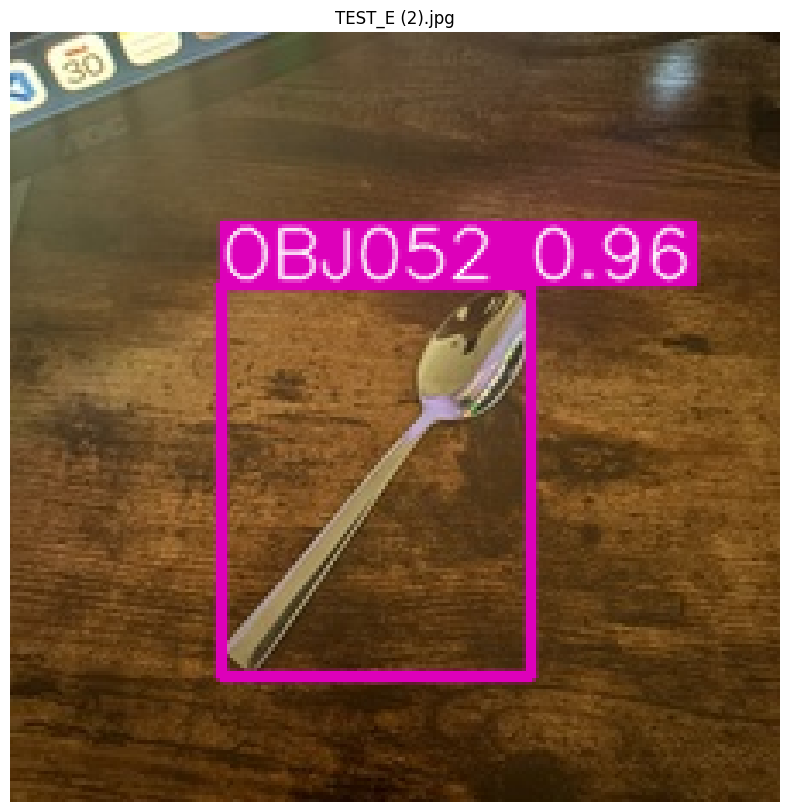

,object_id,object_name,confidence,x1,y1,x2,y2,row,col
0,OBJ052,Spoon,0.96,61,74,152,187,1,1



TEST_J (2).jpg: 1 objects found (single photo, with TTA)


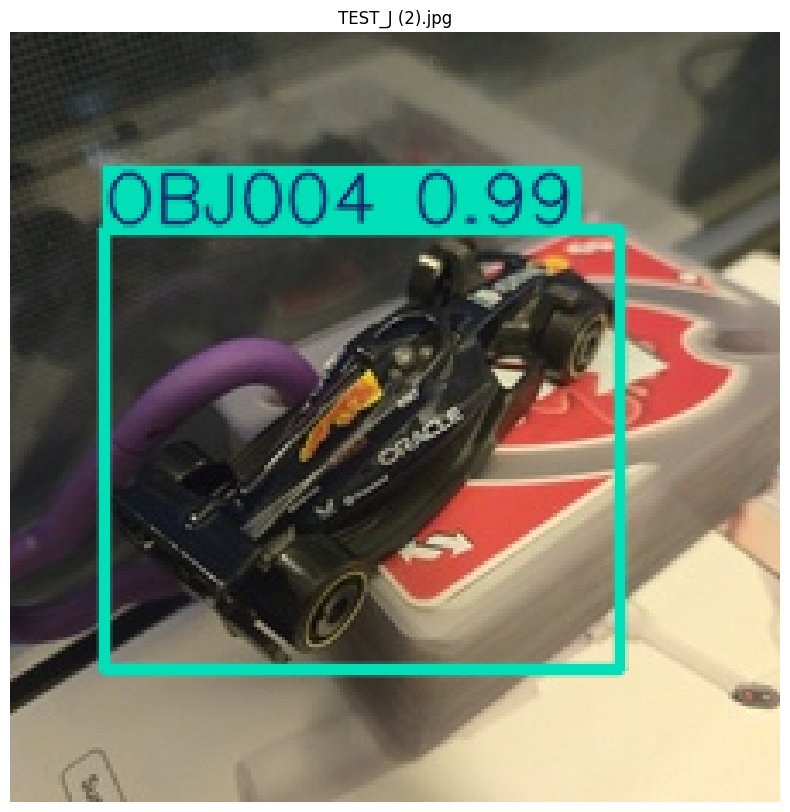

,object_id,object_name,confidence,x1,y1,x2,y2,row,col
0,OBJ004,Toy Car,0.99,27,58,178,186,1,1



test (2).jpg: 0 objects found (single photo, with TTA)


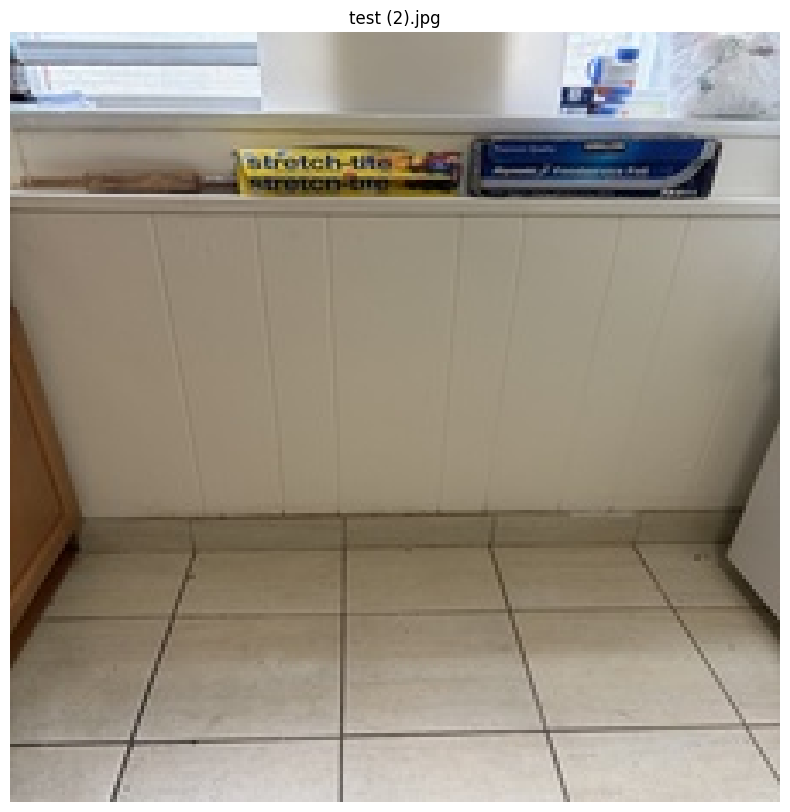

,object_id,object_name,confidence,x1,y1,x2,y2,row,col


In [28]:
# ===== Milestone 3: run the trained model on new images =====
import os, sys, json
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from google.colab import drive, files
drive.mount("/content/drive")
!pip -q install ultralytics
from ultralytics import YOLO

RUNS = "/content/drive/MyDrive/milestone3_v2/runs"
MODEL = next(p for p in [f"{RUNS}/final_yolov8s_{v}/weights/best.pt" for v in ("v4", "v3", "v2")] if os.path.exists(p))
RULE_FILE = "/content/drive/MyDrive/milestone3_v2/demo_conf.json"   # written by 3.2.3
TTA_FILE = "/content/drive/MyDrive/milestone3_v2/single_photo_tta.json"   # written by 3.2.2
model = YOLO(MODEL)
CONF, TILE = 0.5, 224
rule = json.load(open(RULE_FILE)) if os.path.exists(RULE_FILE) else {}
FLOOR = rule["floor"] if rule.get("model") == MODEL else CONF   # chosen on the validation grids for this model
print("model:", MODEL, "| floor for the most confident box of each cell:", FLOOR)
TTA = os.path.exists(TTA_FILE) and json.load(open(TTA_FILE))["use_tta"]   # single photos only
OBJECT_NAMES = {   # same as PROMPTS in 2.5 (OBJECT_NAME from the class sheet), copied so this cell runs on its own
    "OBJ001": "Basketball", "OBJ002": "Water Bottle", "OBJ003": "NoteBook", "OBJ004": "Toy Car",
    "OBJ005": "Computer Mouse", "OBJ006": "Capybara Toy", "OBJ007": "Apple", "OBJ008": "Cat",
    "OBJ009": "Marshall Speaker", "OBJ010": "Nike Sneakers", "OBJ011": "Mug", "OBJ012": "Computer Keyboard",
    "OBJ013": "Mobile Phone", "OBJ014": "Sunglasses", "OBJ015": "Water Tumbler", "OBJ016": "Sandisk Portable SSD",
    "OBJ017": "Controller", "OBJ018": "Rubiks Cube", "OBJ019": "Plant", "OBJ020": "Airpod",
    "OBJ021": "Toy Bunny", "OBJ022": "Guitar", "OBJ023": "Bracelet", "OBJ024": "Plush Doll",
    "OBJ025": "Watch", "OBJ026": "Red Sox Cap", "OBJ027": "Tennis Ball", "OBJ028": "Banana",
    "OBJ029": "Orange", "OBJ030": "Tennis Racket", "OBJ031": "UNO Card Box", "OBJ032": "Sound Card",
    "OBJ033": "Duck", "OBJ034": "Table Tennis Racket", "OBJ035": "Badminton Racket", "OBJ036": "Pencil Case",
    "OBJ037": "Candle", "OBJ038": "Perfume Bottle", "OBJ039": "Scissors", "OBJ040": "Clutcher",
    "OBJ041": "Table Fan", "OBJ042": "Mouth Guard Case", "OBJ043": "Swimming Goggles", "OBJ044": "Anime Figurine",
    "OBJ045": "Wayfarer Sunglasses", "OBJ046": "IWatch", "OBJ047": "Backpack", "OBJ048": "Wireless Powerbank",
    "OBJ049": "Pickleball Bat", "OBJ050": "Hairbrush", "OBJ051": "Tissue", "OBJ052": "Spoon",
    "OBJ053": "Moisturizer", "OBJ054": "Purse", "OBJ055": "Scientific Calculator", "OBJ056": "Trader Joe's Bag",
    "OBJ057": "Power Bank", "OBJ058": "Footstool", "OBJ059": "Comb", "OBJ060": "Sleep Mask",
    "OBJ061": "Card Wallet", "OBJ062": "Headphones", "OBJ063": "Measuring Bottle", "OBJ064": "RGB Projector",
    "OBJ065": "Analog Watch", "OBJ066": "Hair Oil", "OBJ067": "Men's Wallet", "OBJ068": "Neck Pillow",
    "OBJ069": "Knife", "OBJ070": "Astronaut Projector", "OBJ071": "Sloth Plushie", "OBJ072": "Dog",
    "OBJ073": "Bowl",
}


def one_per_cell(r, floor, cell):   # same rule as 3.2.3: keep the most confident box of each cell, if >= floor
    best = {}
    for i, (s, b) in enumerate(zip(r.boxes.conf.tolist(), r.boxes.xyxy.tolist())):
        k = (int((b[0] + b[2]) / 2 // cell), int((b[1] + b[3]) / 2 // cell))
        if s >= floor and (k not in best or s > best[k][0]):
            best[k] = (s, i)
    return r[sorted(i for _, i in best.values())]


for name, data in files.upload().items():          # pick all 5 images at once
    open(name, "wb").write(data)
    img = ImageOps.exif_transpose(Image.open(name)).convert("RGB")
    small = max(img.size) <= 336                       # a single 224 px photo
    grid = not small and img.width % TILE == 0 and img.height % TILE == 0
    r = model.predict(img, imgsz=448 if small else 1120, conf=min(FLOOR, CONF), augment=small and TTA, verbose=False)[0]
    if small or grid:   # a single photo is one cell
        r = one_per_cell(r, FLOOR, max(img.size) if small else TILE)
    else:
        r = r[[i for i, s in enumerate(r.boxes.conf.tolist()) if s >= CONF]]
    rows = [dict(object_id=model.names[int(c)], object_name=OBJECT_NAMES.get(model.names[int(c)], ""),
                 confidence=round(float(s), 2),
                 x1=round(b[0]), y1=round(b[1]), x2=round(b[2]), y2=round(b[3]),
                 row=int((b[1] + b[3]) / 2 // TILE) + 1, col=int((b[0] + b[2]) / 2 // TILE) + 1)
            for c, s, b in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())]
    det = pd.DataFrame(rows, columns=["object_id", "object_name", "confidence", "x1", "y1", "x2", "y2", "row", "col"])
    det = det.sort_values(["row", "col"]).reset_index(drop=True)
    print(f"\n{name}: {len(det)} objects found" + (" (single photo, with TTA)" if small and TTA else ""))
    plt.figure(figsize=(10, 10)); plt.imshow(r.plot()[..., ::-1]); plt.axis("off"); plt.title(name); plt.show()
    display(det)
    det.to_csv(name.rsplit(".", 1)[0] + "_detections.csv", index=False)